# ORIE 5380 · An introduction to Gurobi in Python

We will build a bag-production model, then compare a feasible network flow
with a minimum-cost flow. Work through the notebook one cell at a time.

**Open this notebook in Google Colab:** download the file from Canvas, visit
[Google Colab](https://colab.research.google.com/), and choose **File → Upload notebook**.
Select this `.ipynb` file from your Downloads folder, then click **Connect**.
Run the first supplied cell using its triangle button. Expect
`Ready for class: x = 1.0 objective = 1.0`.

Save a working copy to Google Drive. Re-run the setup cell after starting a new
runtime. During class, complete and run one guided cell at a time.
Double-clicking the downloaded file is not the setup route for Colab.

This is the **class starter**. Replace each `___` using the nearby comments.
Complete a cell's gaps before running it; finish all gaps before **Run All**.

All the lesson models are small enough for the free license included with `gurobipy`.
For this introduction, a `Restricted license` startup message is expected.
You do not need to activate a separate academic license for these examples.
[Gurobi's Colab setup guide](https://support.gurobi.com/hc/en-us/articles/4409582394769-Google-Colab-Installation-and-Licensing).

**Optional extension:** After Homework 4, reuse the arrows for a maximum-flow
problem. We will verify its answer with a matching minimum cut, using newly
assigned capacities. This section can replace the separate bounds preview
in a 60-minute class, or be saved for the next lecture.

**Lesson order:** Homework 2 continuous bags → whole bags with INTEGER → Homework 4 feasible and minimum-cost flow → optional maximum flow and minimum cut → bounds → LLM guidance. Choose extensions to fit the class time.


In [1]:
# Supplied setup: run this cell before the modeling cells.
%pip install -q gurobipy

import gurobipy as gp
from gurobipy import GRB

# A tiny test checks that the package can actually solve a model.
with gp.Model("setup_check") as check:
    check.Params.OutputFlag = 0
    check_x = check.addVar(ub=1, name="check_x")
    check.setObjective(check_x, GRB.MAXIMIZE)
    check.optimize()
    if check.Status == GRB.OPTIMAL:
        print("Ready for class: x =", check_x.X, "objective =", check.ObjVal)
    else:
        print("Setup check status:", check.Status)


Note: you may need to restart the kernel to use updated packages.
Restricted license - for non-production use only - expires 2027-11-29
Ready for class: x = 1.0 objective = 1.0


### Why move from Excel Solver to Gurobi?

Excel Solver is a good choice for our small examples. Python makes it easier to
build a model from data, repeat it for different scenarios, and inspect the code.

**A real example of scale:** A published farm-planning LP with **50,827 variables
and 4,081 constraints** solved in about **1.4 seconds with Gurobi** in the authors'
experiment. Standard Excel Solver allows **200 variable cells**.
([Study, Section 5](https://www.sciencedirect.com/science/article/pii/S2772662225000888);
[Microsoft's limit](https://support.microsoft.com/en-us/excel/define-and-solve-a-problem-by-using-solver).)

That is a reported runtime for one model and computer. Other spreadsheet
solver add-ins can handle larger models; problem structure and formulation also
affect runtime. We will use small models today so we can understand every row.

## Before we code

Think back to Excel Solver: we needed decision variables, constraints, and an
objective. We will describe those same three pieces in Python.

**Discuss:** Which pieces determine whether a solution is allowed? Which piece
tells us what makes one allowed solution better than another?

## 1. How many bags should we produce?

We will use the bag-production problem from [Homework 2](https://canvas.cornell.edu/courses/88614/assignments/1015613).
Let $h$ be the number of handbags and $s$ the number of shoulder bags.
The homework allows fractional quantities, so this is a **linear program (LP)**.

$$
\begin{alignedat}{3}
\text{maximize}\quad & 5.5h+s \\[6pt]
\text{subject to}\quad & h           &\;&\ge &\;&10 \\
                      & 5h+s        &&\le &&200 \\
                      & 2.5h+4s     &&\ge &&125 \\
                      & 3s          &&\le &&90+2h \\
                      & h,s         &&\ge &&0.
\end{alignedat}
$$

Each handbag earns \$5.50 and each shoulder bag earns \$1. Machine time is limited
to 200 minutes, while at least 125 inches of leftover leather must be used.
Shoulder bags use fabric; each handbag recovers 2 inches in addition to the
90 inches already available.

**Discuss:** Why is the leather inequality different from the machine inequality?
Why does the available fabric depend on $h$?

### Create the model and its decision variables

The imports and model name are supplied. Complete the lower bounds for `h` and `s`
so neither quantity can be negative. `GRB.CONTINUOUS` allows fractional values.

**Check:** Have we assigned production quantities yet, or only defined the unknowns?

In [2]:
import gurobipy as gp
from gurobipy import GRB

m = gp.Model("bags")

# Replace each ___ with a lower bound that prevents negative production.
h = m.addVar(lb=0, vtype=GRB.CONTINUOUS, name="h")
s = m.addVar(lb=0, vtype=GRB.CONTINUOUS, name="s")

### Meet the retailer's minimum order

We must produce at least 10 handbags. Complete the expression inside `addConstr`
using `h`, a comparison sign, and 10.

**Before running:** Read your inequality aloud. Does it express “at least”?

In [3]:
# We must produce at least 10 handbags.
# Replace ___ with a comparison between h and 10.
m.addConstr(h >= 10, name="retailer_promise")

<gurobi.Constr *Awaiting Model Update*>

### Stay within the machine capacity

A handbag takes 5 minutes and a shoulder bag takes 1 minute. Complete the
constraint that keeps total machine time within the 200 minutes available.

We save this constraint as `machine` so we can change its capacity in a later experiment.

In [4]:
# Total machine time is 5 * h + s, with 200 minutes available.
# Replace ___ with the complete inequality that respects this capacity.
machine = m.addConstr(5 * h + s <= 200, name="machine_minutes")

### Use enough leftover leather

Each handbag uses 2.5 inches of leather and each shoulder bag uses 4 inches.
Complete the missing coefficient and the minimum-use requirement.

**Discuss:** What would change if we used `<=` instead of `>=`?

In [9]:
# A shoulder bag uses how many inches? What is the minimum total use?
# Complete the coefficient and the right-hand side.
m.addConstr(2.5 * h + 4 * s >= 125, name="leather_minimum")

<gurobi.Constr *Awaiting Model Update*>

### Account for recovered fabric

Shoulder bags use 3 inches each. The available fabric is the original 90 inches
plus the amount recovered from handbags. Complete that recovery coefficient.

**Check:** Can you identify “fabric used” and “fabric available” in the code?

In [10]:
# Each handbag adds fabric to the 90 inches already available.
# Replace ___ with the amount recovered per handbag.
m.addConstr(3 * s <= 90 + 2 * h, name="fabric_stock")

<gurobi.Constr *Awaiting Model Update*>

### Choose the best production plan

The revenue expression is supplied. Complete the direction using `GRB.MAXIMIZE`
or `GRB.MINIMIZE`.

**Discuss:** Why are we maximizing revenue here rather than profit?

In [11]:
# The revenue expression is supplied. Should we maximize or minimize it?
# Replace ___ with MAXIMIZE or MINIMIZE.
m.setObjective(5.5 * h + s, GRB.MAXIMIZE)

### Solve the model and read the answer

Complete the method name that starts the solve, then run the cell. The supplied
`if` block reads solution values only when the status is `GRB.OPTIMAL`.

`h.X` and `s.X` are the chosen quantities. `m.ObjVal` is their total revenue.

In [12]:
# Replace ___ with the method that starts the solver, then run the cell.
m.optimize()

# Read solution values only after an optimal solve.
if m.Status == GRB.OPTIMAL:
    print("Handbags =", h.X)
    print("Shoulder bags =", s.X)
    print("Revenue =", m.ObjVal)
else:
    print("Solve status:", m.Status)

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Optimize a model with 6 rows, 2 columns and 11 nonzeros (Max)
Model has 2 linear objective coefficients
Coefficient statistics:
  Matrix range     [1e+00, 5e+00]
  Objective range  [1e+00, 6e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+01, 2e+02]

LP warm-start: use basis

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    2.2000000e+02   6.250000e+00   0.000000e+00      0s
       1    2.1928571e+02   0.000000e+00   0.000000e+00      0s

Solved in 1 iterations and 0.01 seconds (0.00 work units)
Optimal objective  2.192857143e+02
Handbags = 38.57142857142857
Shoulder bags = 7.142857142857144
Revenue = 219.28571428571428


### What does `.X` mean?

`h` is a Gurobi decision-variable object: it represents an unknown while we build
the model. After a successful solve, **`h.X` reads its numerical value in the
current solution**. Here, `h.X` is about 38.5714. `m.ObjVal` reads the whole
model's objective value, about 219.2857.

The same notation applies to network flows: `ac` represents flow on $a\to c$;
`ac.X` reads how much Gurobi chose to send on that arc. In our minimum-cost
solution, `ac.X` is 0 and `ad.X` is 6.

Use the variable object in constraints, such as `5 * h + s <= 200`. Read `.X`
after solving and checking status. Reading it before a solution exists can raise
an error. The supplied reports use `if m.Status == GRB.OPTIMAL:` for this reason.

[Gurobi's definition of X](https://docs.gurobi.com/projects/optimizer/en/current/reference/attributes/variable.html#attrx).

### Read the first solver log

**`Inf.` abbreviates infeasibility. It does not mean infinity.**

```text
Presolve removed 4 rows and 2 columns
Presolve time: 0.00s
Presolve: All rows and columns removed
Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    2.1928571e+02   0.000000e+00   0.000000e+00      0s
```

| Field | How to read it |
|---|---|
| Presolve | Simplifies the model before the main algorithm. Here it resolves the entire tiny LP; the original constraints have not been ignored. |
| Iteration 0 | No further simplex iterations were needed after presolve. |
| Objective | `2.1928571e+02` means $2.1928571\times10^2$, about 219.2857. |
| Primal Inf. | Sum of constraint and bound violations for the current basis; zero means primal feasibility. |
| Dual Inf. | Sum of dual-feasibility violations; zero means dual feasibility. We will study the dual later. |
| Time 0s | The displayed elapsed time is rounded; this is a very small model. |

For an LP simplex basis, primal and dual feasibility together establish
optimality within numerical tolerances. Check the final status and summary too.
**`Dual Inf.` is not the primal–dual objective gap.**

<details>
<summary>What do the coefficient statistics mean?</summary>

These are ranges of coefficient magnitudes, not solution values. `1e+00` means 1;
`2e+02` means 200. The displayed endpoints are rounded.

- **Matrix range [1, 5]:** nonzero coefficients in the constraint rows.
- **Objective range [1, 6]:** nonzero objective coefficients; 5.5 is displayed as `6e+00`.
- **Bounds range [0, 0]:** no nonzero finite variable bounds to summarize here. Our variables have lower bound 0 and no finite upper bound; `h >= 10` is a constraint row. This does not say the solution values are zero.
- **RHS range [10, 200]:** nonzero right-hand-side magnitudes, such as 10, 125, 90, and 200.

</details>

References: [simplex log](https://docs.gurobi.com/projects/optimizer/en/current/concepts/logging/simplex.html)
and [presolve removing all rows and columns](https://support.gurobi.com/hc/en-us/articles/360038213152-What-does-Presolve-All-rows-and-columns-removed-mean).

### Check the answer against the original requirements

Run these supplied calculations. Compare each value with its limit or minimum;
for fabric, compare use with availability.

A constraint is **binding** when it holds with equality at the solution.
**Discuss:** Which constraints bind? Does a feasible plan necessarily maximize revenue?

In [13]:
if m.Status == GRB.OPTIMAL:
    print("Machine minutes used =", 5 * h.X + s.X)
    print("Leather inches used =", 2.5 * h.X + 4 * s.X)
    print("Fabric inches used =", 3 * s.X)
    print("Fabric inches available =", 90 + 2 * h.X)

Machine minutes used = 199.99999999999997
Leather inches used = 125.0
Fabric inches used = 21.42857142857143
Fabric inches available = 167.14285714285714


## 2. What if bags must come in whole numbers? · Optional extension

Our first model allowed fractional bags because Homework 2 explicitly permits
them. For a new scenario, keep all its data but require whole bags.

**Mixed-integer programming (MIP)** handles models with some or all decision
variables restricted to integers. Our example makes both counts integer, so it
is an integer linear program, a special case of MIP. If another variable remained
continuous, the model would mix integer and continuous variables.

$$
\begin{alignedat}{3}
\text{maximize}\quad &5.5h+s \\[6pt]
\text{subject to}\quad &h        &\;&\ge &\;&10 \\
                      &5h+s     &&\le &&200 \\
                      &2.5h+4s  &&\ge &&125 \\
                      &3s       &&\le &&90+2h \\
                      &h,s      &&\in &&\mathbb{Z}_{\ge0}.
\end{alignedat}
$$

In `gurobipy`, write `vtype=GRB.INTEGER` when creating a variable. Other continuous
variables can still use `GRB.CONTINUOUS`; a yes/no decision can use `GRB.BINARY`.

Allow about 6–8 minutes. Continue with the bag model before moving to Homework 4.
This section does not depend on the optional maximum-flow section.

### Why not just round the linear-program solution?

The continuous solution was about $h=38.5714$, $s=7.1429$. Before running this
supplied cell, predict what happens if we round both values to the nearest integer.

**Check:** Does rounding preserve every constraint? Run the original bag model
first if you skipped that part of the notebook.

In [14]:
# Use the original continuous bag solution to try ordinary rounding.
if m.Status == GRB.OPTIMAL:
    rounded_h = round(h.X)
    rounded_s = round(s.X)
    rounded_machine_use = 5 * rounded_h + rounded_s
    print("Rounded plan:", rounded_h, "handbags and", rounded_s, "shoulder bags")
    print("Machine minutes:", rounded_machine_use, "out of 200")
    print("Machine constraint satisfied?", rounded_machine_use <= 200)
else:
    print("Run the continuous bag model before this comparison.")

Rounded plan: 39 handbags and 7 shoulder bags
Machine minutes: 202 out of 200
Machine constraint satisfied? False


The rounded plan is $h=39$, $s=7$. It needs

$$5(39)+7=202>200\text{ machine minutes}.$$

It is a whole-number plan, but it is infeasible. Setting a variable's type tells
Gurobi to find the best whole-number plan **while satisfying all the constraints**.

### Require integer decision variables

Create a new model and complete the two variable types. Use `GRB.INTEGER` for
both production counts. The original continuous model stays available for comparison.

**Discuss:** Which part of the model changed? Do the resource coefficients need to change?

In [16]:
import gurobipy as gp
from gurobipy import GRB

# Build a separate model so we can compare it with the continuous solution.
bags_mip = gp.Model("whole_bags")
# Replace both ___ markers with the type that requires whole-number values.
h_int = bags_mip.addVar(lb=0, vtype=GRB.INTEGER, name="h_int")
s_int = bags_mip.addVar(lb=0, vtype=GRB.INTEGER, name="s_int")

### Solve with the same objective and requirements

The constraints and objective are supplied. Run the cell after completing the
variable types. Gurobi will recognize the integer variables and use its MIP solver.

**Predict:** Can restricting the feasible set to whole-number plans improve the
maximum revenue beyond the continuous model's value?

In [17]:
# The requirements and revenue are exactly the same as in the original model.
bags_mip.addConstr(h_int >= 10, name="retailer_promise")
bags_mip.addConstr(5 * h_int + s_int <= 200, name="machine_minutes")
bags_mip.addConstr(2.5 * h_int + 4 * s_int >= 125, name="leather_minimum")
bags_mip.addConstr(3 * s_int <= 90 + 2 * h_int, name="fabric_stock")
bags_mip.setObjective(5.5 * h_int + s_int, GRB.MAXIMIZE)
bags_mip.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Optimize a model with 4 rows, 2 columns and 7 nonzeros (Max)
Model fingerprint: 0xb340c35f
Model has 2 linear objective coefficients
Variable types: 0 continuous, 2 integer (0 binary)
Coefficient statistics:
  Matrix range     [1e+00, 5e+00]
  Objective range  [1e+00, 6e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+01, 2e+02]

Presolve removed 1 rows and 0 columns
Presolve time: 0.01s
Presolved: 3 rows, 2 columns, 6 nonzeros
Variable types: 0 continuous, 2 integer (0 binary)
Found heuristic solution: objective 219.0000000

Root relaxation: cutoff, 0 iterations, 0.00 seconds (0.00 work units)

Explored 1 nodes (0 simplex iterations) in 0.02 seconds (0.00 work units)
Thread count was 10 (of 10 available processors)

Solution count 1: 219 

Optimal solution found (tolerance 1.00e-04)
Best o

### Compare the answers and read the MIP gap

Run the report, then check the whole-number answer against the original requirements.
Integer solution values may print as `38.0`; that display still represents a whole number.

For a maximization MIP, the best feasible integer plan gives a **lower bound**.
The solver's `ObjBound` gives an **upper bound**. `MIPGap` compares these bounds;
we multiply it by 100 to display a percentage.

In [18]:
if bags_mip.Status == GRB.OPTIMAL:
    print("Whole handbags =", h_int.X)
    print("Whole shoulder bags =", s_int.X)
    print("Revenue =", bags_mip.ObjVal)
    print("Best bound =", bags_mip.ObjBound)
    print("MIP gap (%) =", 100 * bags_mip.MIPGap)
    print("Machine minutes used =", 5 * h_int.X + s_int.X)
    print("Leather inches used =", 2.5 * h_int.X + 4 * s_int.X)
    print("Fabric inches used =", 3 * s_int.X)
    print("Fabric inches available =", 90 + 2 * h_int.X)
else:
    print("Solve status:", bags_mip.Status)

Whole handbags = 38.0
Whole shoulder bags = 10.0
Revenue = 219.0
Best bound = 219.0
MIP gap (%) = 0.0
Machine minutes used = 200.0
Leather inches used = 135.0
Fabric inches used = 30.0
Fabric inches available = 166.0


### What did integrality change?

| Model or plan | Handbags | Shoulder bags | Revenue | What does it tell us? |
|---|---:|---:|---:|---|
| Continuous optimum | 38.5714 | 7.1429 | 219.2857 | An upper bound on the whole-bag optimum |
| Nearest-integer rounding | 39 | 7 | 221.50 | Infeasible: it needs 202 machine minutes |
| Integer optimum | 38 | 10 | 219.00 | A feasible, optimal whole-bag plan |

The integer answer uses 200 machine minutes and 135 inches of leather. It uses
30 inches of fabric, with 166 available. It satisfies every requirement.

**Reading the log:** In a MIP log, look for the incumbent (best feasible integer
objective), best bound, and gap. This tiny example may solve in presolve, so it
may not show a long search. At the end, both the objective and `ObjBound` are 219.

The final MIP gap is zero even though the continuous optimum is 219.2857.
The difference between the LP and integer optima is a different comparison:
the solver can tighten its bound on the integer problem beyond the original LP bound.

**Check your understanding:** Why can rounding give a number larger than the LP
optimum without contradicting optimality? Which constraint did that plan violate?

References: [variable types](https://docs.gurobi.com/projects/optimizer/en/current/concepts/modeling/variables.html)
and [MIP log interpretation](https://docs.gurobi.com/projects/optimizer/en/current/concepts/logging/mip.html).

## 3. Can we route the supply, and at what cost?

Now consider the directed network from [Homework 4](https://canvas.cornell.edu/courses/88614/assignments/1026114).
Each arrow gets one nonnegative continuous flow variable. For example, `ac`
is the flow from $a$ to $c$. There are no limits on individual arc flows.

| Node | a | b | c | d | e | f |
|---|---:|---:|---:|---:|---:|---:|
| Net supply | 0 | 3 | −4 | −6 | 5 | 2 |

A positive value means supply; a negative value means demand. At every node,

$$\text{outflow}-\text{inflow}=\text{net supply}.$$

| Arc | ac | ad | ba | bc | ce | db | ea | fb | fd |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Cost per unit | 0 | 1 | 8 | 3 | 2 | 5 | 2 | 0 | 10 |

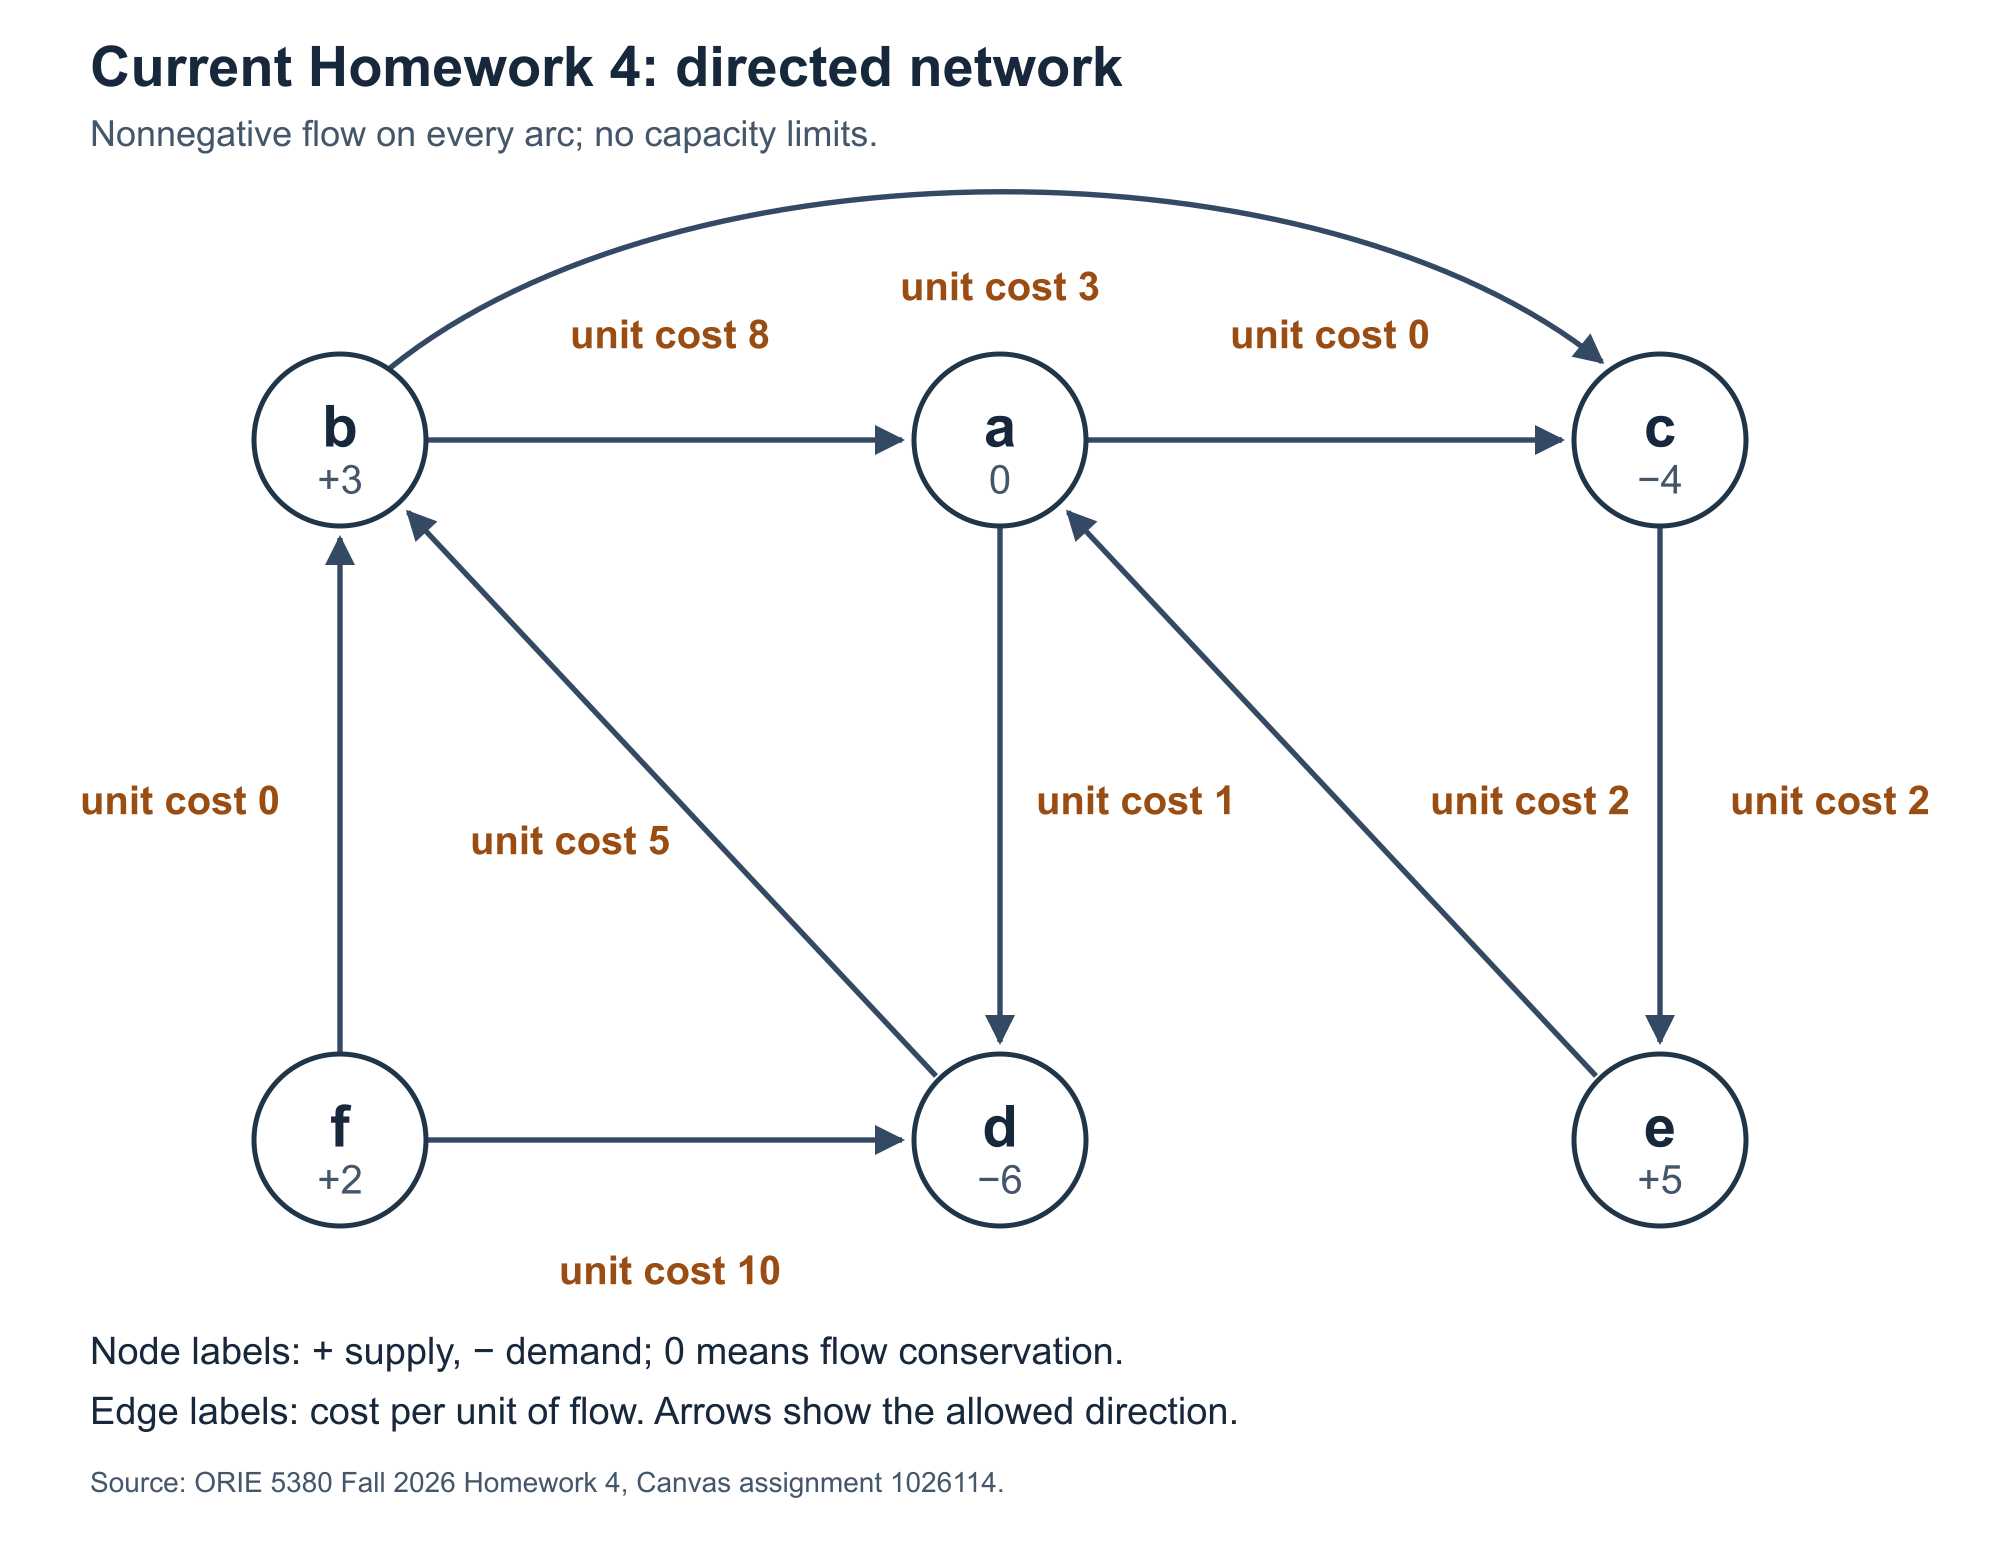

**Pause here:** List the arrows entering and leaving $b$ and $c$.
Which node should have a negative right-hand side?

### Why do we require nonnegative flow?

Here, $x_{ad}$ means **quantity sent along the allowed arrow $a\to d$**.
It can be zero or positive. A negative value would introduce travel from $d$ to
$a$, which the homework graph does not allow.

There is also a cost issue: the term $1x_{ad}$ would charge $-2$ if $x_{ad}=-2$.
That is a credit, not the positive shipping cost we usually mean for two units
traveling in the reverse direction.

**Your signed-flow idea is valid for a different model.** On a link that really
allows both directions, a signed variable can measure net flow relative to a
chosen reference direction. Its bounds and cost must represent both directions.
For example, equal unit shipping cost $c$ in either direction gives cost $c|z|$,
not $cz$.

A simple LP approach is to give each allowed direction its own nonnegative
variable:

$$x_{ad}\ge0,\qquad x_{da}\ge0,\qquad
\text{cost}=c_{ad}x_{ad}+c_{da}x_{da}.$$

Net flow from $a$ toward $d$ is then $x_{ad}-x_{da}$. The two directions can have
different costs and capacities. Add $d\to a$ only if the actual problem allows it.

**Check:** Does choosing a reference direction for a signed variable create
permission to ship both ways on a one-way route?

### Check one proposed flow

Read **quantity** (blue) separately from **unit cost** (brown). An arc contributes quantity × unit cost to the objective.

Before asking for the cheapest flow, let us check whether this proposed plan
satisfies every node balance.

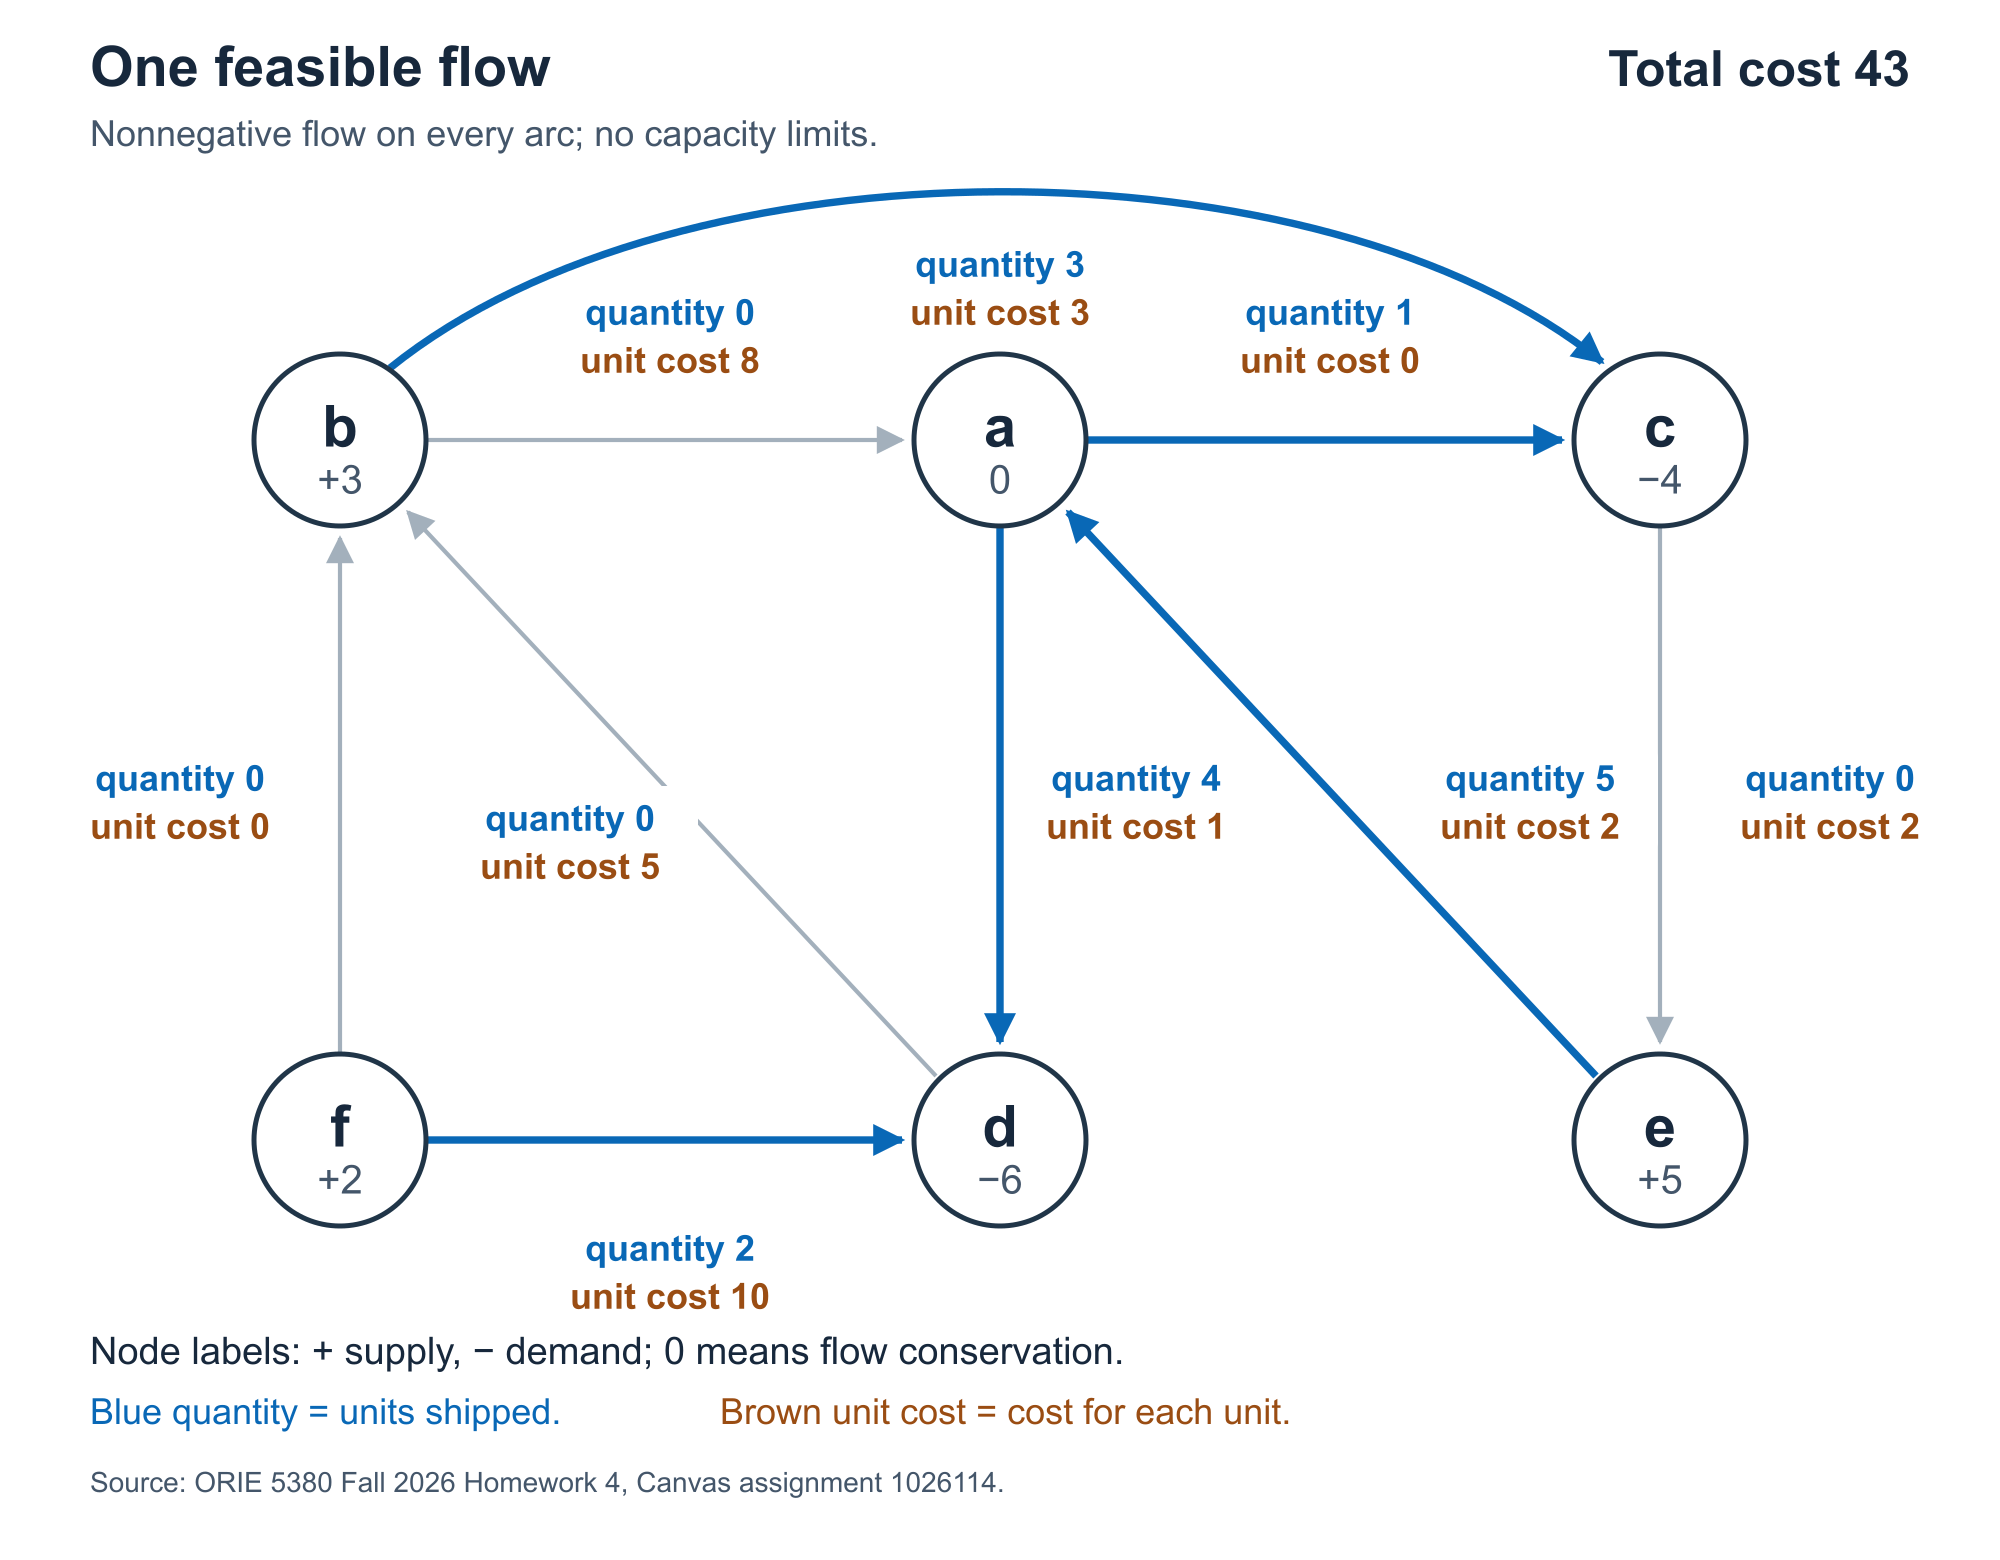

The positive flows are $x_{ac}=1$, $x_{ad}=4$, $x_{bc}=3$, $x_{ea}=5$, and
$x_{fd}=2$. All other flows are zero. Its total cost is

$$0(1)+1(4)+3(3)+2(5)+10(2)=43.$$

**Try it:** Check the balances at $b$ and $c$, then check another node with a partner.
Does satisfying all the balances tell us this plan is cheapest?

### Create one flow variable for each arrow

These declarations are supplied. Run the cell and match the two-letter variable
names to the arrows in the diagram. The lower bounds keep every flow nonnegative.

**Check:** Which direction does `ac` represent?

In [19]:
net = gp.Model("hw4_network")
ac = net.addVar(lb=0, vtype=GRB.CONTINUOUS, name="ac")
ad = net.addVar(lb=0, vtype=GRB.CONTINUOUS, name="ad")
ba = net.addVar(lb=0, vtype=GRB.CONTINUOUS, name="ba")
bc = net.addVar(lb=0, vtype=GRB.CONTINUOUS, name="bc")
ce = net.addVar(lb=0, vtype=GRB.CONTINUOUS, name="ce")
db = net.addVar(lb=0, vtype=GRB.CONTINUOUS, name="db")
ea = net.addVar(lb=0, vtype=GRB.CONTINUOUS, name="ea")
fb = net.addVar(lb=0, vtype=GRB.CONTINUOUS, name="fb")
fd = net.addVar(lb=0, vtype=GRB.CONTINUOUS, name="fd")

### Start with a node that conserves flow

Node $a$ has no supply or demand of its own, so its outgoing flow must equal its
incoming flow. Read the supplied constraint before running it.

**Check:** Can you find all four arrows that appear in this row?

In [20]:
net.addConstr(ac + ad - ba - ea == 0, name="balance_a")

<gurobi.Constr *Awaiting Model Update*>

### Complete the balance at a supply node

Node $b$ supplies 3 units. The scaffold includes its outgoing arcs and one
incoming arc. Fill in the other incoming arc and the signed right-hand side.

**Before running:** Check that every arrow touching $b$ appears exactly once.

In [21]:
# Outgoing: ba and bc. Incoming: two arrows end at b.
# Fill in the missing incoming arc and the signed supply of node b.
net.addConstr(ba + bc - db - fb == 3, name="balance_b")

<gurobi.Constr *Awaiting Model Update*>

### Complete the balance at a demand node

Node $c$ needs 4 units. Its incoming and outgoing arcs are supplied; complete
the signed right-hand side using the same outflow-minus-inflow convention.

**Discuss:** Why should the right-hand side be negative?

In [22]:
# Node c needs 4 units. Keep the outflow-minus-inflow convention.
# Complete the signed right-hand side.
net.addConstr(ce - ac - bc == -4, name="balance_c")

<gurobi.Constr *Awaiting Model Update*>

### Check the remaining node balances

The constraints for $d$, $e$, and $f$ are supplied. Match their signs to the node
table, then run the cell. We now have a balance for all six nodes.

**Check:** A node's net supply is not a limit on its total outgoing flow.

In [23]:
net.addConstr(db - ad - fd == -6, name="balance_d")
net.addConstr(ea - ce == 5, name="balance_e")
net.addConstr(fb + fd == 2, name="balance_f")

<gurobi.Constr *Awaiting Model Update*>

### First, ask for any feasible flow

We use a constant objective of zero because our first question is simply
whether the requirements can be met. Run the cell after completing all six balances.

**Discuss:** Every feasible flow has objective zero here. What does `OPTIMAL`
tell us about feasibility, and what does it tell us about the actual arc costs?

In [24]:
net.setObjective(0)     #set it to 0 to make any feasible solution
net.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Optimize a model with 6 rows, 9 columns and 18 nonzeros (Min)
Model fingerprint: 0xfdf72f16
Model has 0 linear objective coefficients
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [0e+00, 0e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [2e+00, 6e+00]

Presolve removed 3 rows and 3 columns
Presolve time: 0.00s
Presolved: 3 rows, 6 columns, 12 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    0.0000000e+00   0.000000e+00   0.000000e+00      0s
       0    0.0000000e+00   0.000000e+00   0.000000e+00      0s

Solved in 0 iterations and 0.00 seconds (0.00 work units)
Optimal objective  0.000000000e+00


### Inspect the flow that the solver found

Run the supplied report. It prints the flows and calculates their actual arc cost
separately from the zero objective used in this phase.

Your flow may differ from the proposed cost-43 plan. That is fine: we asked for
a feasible flow, without asking for the cheapest one.

Remember: `ac` is the variable object; `ac.X` is its current solution value.


In [25]:
if net.Status == GRB.OPTIMAL:
    print("A feasible flow was found; this phase did not minimize cost.")
    print("ac =", ac.X)
    print("ad =", ad.X)
    print("ba =", ba.X)
    print("bc =", bc.X)
    print("ce =", ce.X)
    print("db =", db.X)
    print("ea =", ea.X)
    print("fb =", fb.X)
    print("fd =", fd.X)
    print(
        "Cost of this feasible flow =",
        0 * ac.X + ad.X + 8 * ba.X + 3 * bc.X + 2 * ce.X
        + 5 * db.X + 2 * ea.X + 0 * fb.X + 10 * fd.X,
    )
else:
    print("Solve status:", net.Status)

A feasible flow was found; this phase did not minimize cost.
ac = 4.0
ad = 6.0
ba = 5.0
bc = 0.0
ce = 0.0
db = 0.0
ea = 5.0
fb = 2.0
fd = 0.0
Cost of this feasible flow = 56.0


### Now, minimize the total cost

Keep the variables and balances. Replace the zero objective with cost per unit
times flow on each arc, and choose `GRB.MINIMIZE`.

In the mathematics below, $x_{ac}$ is the Python variable `ac`, and similarly
for the other arrows. The zero-cost arcs still appear in the balances.

$$
\begin{alignedat}{3}
\text{minimize}\quad & x_{ad}+8x_{ba}+3x_{bc}+2x_{ce} \\
                    & {}+5x_{db}+2x_{ea}+10x_{fd} \\[6pt]
\text{subject to}\quad
 & x_{ac}+x_{ad}-x_{ba}-x_{ea} &\;&= &\;&0   \quad\text{(node a)} \\
 & x_{ba}+x_{bc}-x_{db}-x_{fb} &&= &&3   \quad\text{(node b)} \\
 & x_{ce}-x_{ac}-x_{bc}       &&= &&-4  \quad\text{(node c)} \\
 & x_{db}-x_{ad}-x_{fd}       &&= &&-6  \quad\text{(node d)} \\
 & x_{ea}-x_{ce}             &&= &&5   \quad\text{(node e)} \\
 & x_{fb}+x_{fd}             &&= &&2   \quad\text{(node f)} \\
 & x_{ij}                   &&\ge &&0 \quad\text{for every arc }i\to j.
\end{alignedat}
$$

**Check:** Match two objective coefficients to the arc-cost table. Which part
of the model changed?

In [26]:
cost_expr = (
    0 * ac + ad + 8 * ba + 3 * bc + 2 * ce
    + 5 * db + 2 * ea + 0 * fb + 10 * fd
)
net.setObjective(cost_expr, GRB.MINIMIZE)

### Solve the cost-minimization problem

Run `net.optimize()` again after setting the new objective. This time,
`OPTIMAL` refers to minimizing the actual total cost.

**Check:** Find the final status and objective value in the solver output.

In [27]:
net.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Optimize a model with 6 rows, 9 columns and 18 nonzeros (Min)
Model has 7 linear objective coefficients
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e+00, 1e+01]
  Bounds range     [0e+00, 0e+00]
  RHS range        [2e+00, 6e+00]

LP warm-start: use basis

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0   -5.0000000e+30   2.000000e+30   5.000000e+00      0s
       2    3.5000000e+01   0.000000e+00   0.000000e+00      0s

Solved in 2 iterations and 0.00 seconds (0.00 work units)
Optimal objective  3.500000000e+01


### Compare feasibility with optimality

Run the supplied report and compare this cost with the earlier feasible plans.
The constraints have stayed the same; we have changed what we ask the solver to optimize.

**Discuss:** Why can a node with demand still pass some flow onward?

In [28]:
if net.Status == GRB.OPTIMAL:
    print("Minimum cost =", net.ObjVal)
    print("ac =", ac.X)
    print("ad =", ad.X)
    print("ba =", ba.X)
    print("bc =", bc.X)
    print("ce =", ce.X)
    print("db =", db.X)
    print("ea =", ea.X)
    print("fb =", fb.X)
    print("fd =", fd.X)
else:
    print("Solve status:", net.Status)

Minimum cost = 35.0
ac = 0.0
ad = 6.0
ba = 0.0
bc = 5.0
ce = 1.0
db = 0.0
ea = 6.0
fb = 2.0
fd = 0.0


### Interpret the minimum-cost flow

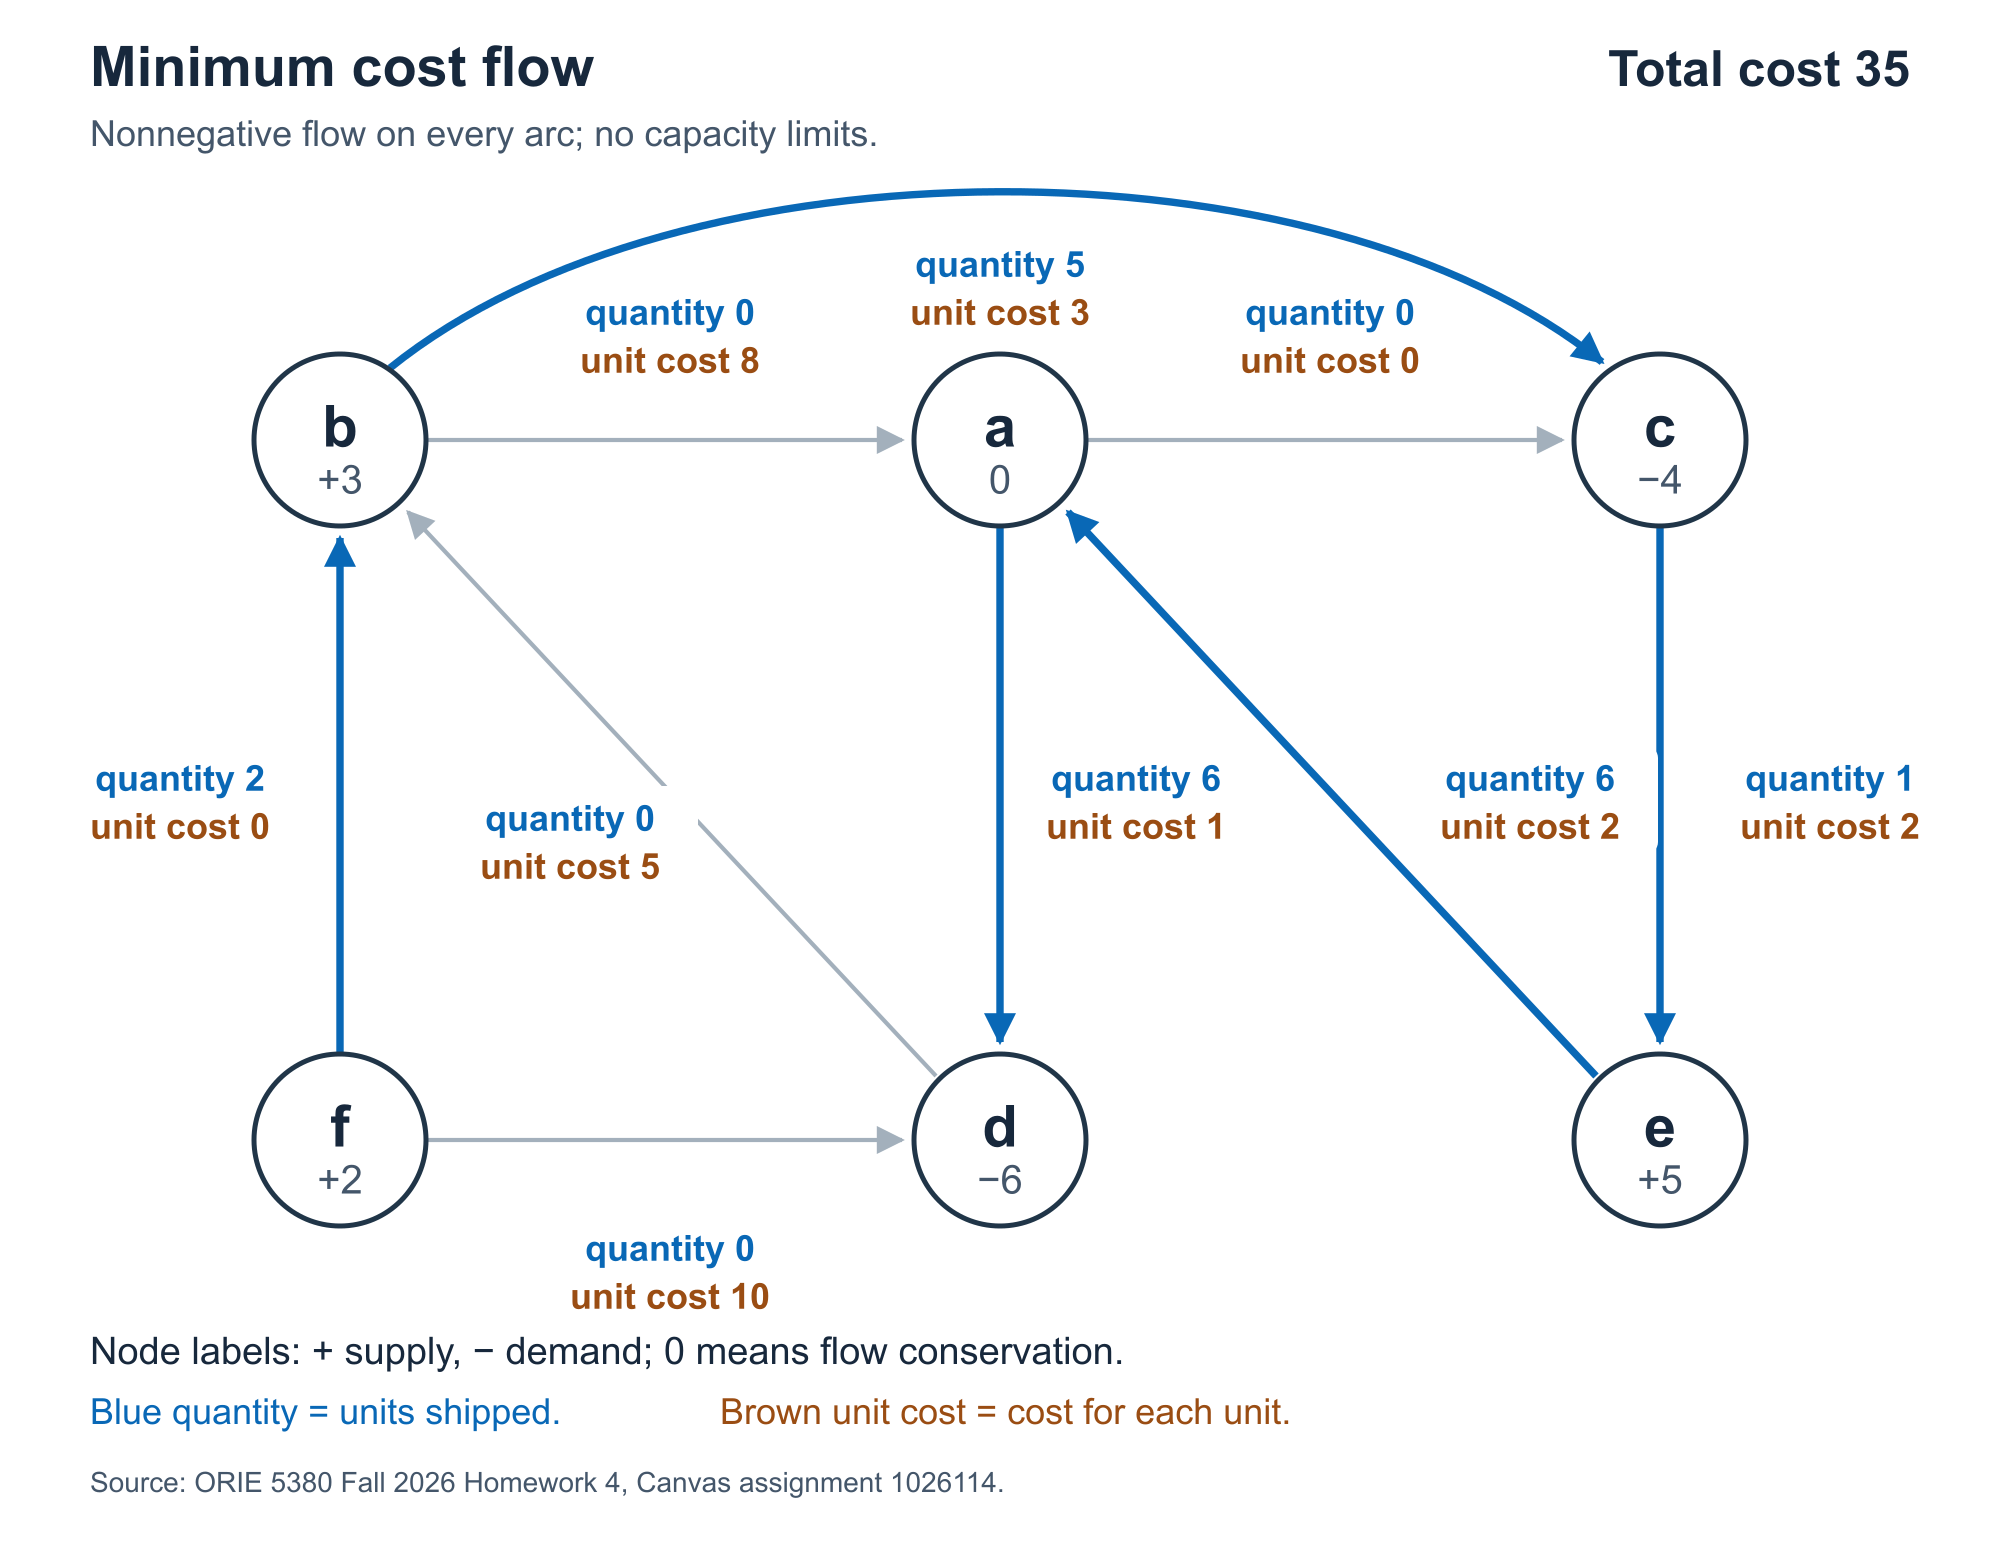

At $c$, 5 units arrive, 4 meet demand, and 1 continues to $e$. At $e$, that
incoming unit joins the node's own supply of 5, so 6 units can leave.

**Check with a partner:** Substitute these flows into the balances at $c$ and $e$.
How do the resulting net flows match the table?

### Homework 4 bonus: what if available supply exceeds demand?

Try a new scenario: increase supply at $e$ from 5 to 7. Total supply is now
$3+7+2=12$, while demand is still $4+6=10$.

If every original balance remains an equality, adding all node equations would
give $0=2$. The internal arc flows cancel, so no feasible solution can exist.

The supplied course text handles this by using **inequalities at supply nodes**
(printed page 55). An alternative is a **dummy demand node**: retain equality
balances and account explicitly for the 2 unused units.

This optional exercise takes about 5–7 minutes. It follows the HW4 solution so
the connection is immediate; use it as an extension or later practice.

In [29]:
# New scenario: node e has 7 units instead of 5. Do not change net itself.
extra_supply = net.copy()
extra_supply.getConstrByName("balance_e").RHS = 7
extra_supply.optimize()
print("Original equality model is infeasible?", extra_supply.Status == GRB.INFEASIBLE)
# There is no solution here, so do not read a variable's .X.

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Optimize a model with 6 rows, 9 columns and 18 nonzeros (Min)
Model fingerprint: 0x6277c02e
Model has 7 linear objective coefficients
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e+00, 1e+01]
  Bounds range     [0e+00, 0e+00]
  RHS range        [2e+00, 7e+00]

Presolve removed 3 rows and 3 columns
Presolve time: 0.00s
Presolved: 3 rows, 6 columns, 12 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    2.0000000e+01   8.000000e+00   0.000000e+00      0s

Solved in 1 iterations and 0.00 seconds (0.00 work units)
Infeasible model
Original equality model is infeasible? True


### Add a dummy node that receives the unused supply

Add virtual zero-cost arcs $b\to g$, $e\to g$, and $f\to g$. They represent
**supply left unused**, not physical shipping to a new customer. Node $g$ has
demand 2. Keep the original demand and transit-node balances unchanged.

$$
\begin{alignedat}{3}
x_{ba}+x_{bc}-x_{db}-x_{fb}+x_{bg} &\;&= &\;&3  &\quad\text{(b)}\\
x_{ea}-x_{ce}+x_{eg}              &&= &&7  &\quad\text{(e)}\\
x_{fb}+x_{fd}+x_{fg}              &&= &&2  &\quad\text{(f)}\\
x_{bg}+x_{eg}+x_{fg}              &&= &&2  &\quad\text{(g receives 2)}\\
x_{bg},x_{eg},x_{fg}              &&\ge &&0.&
\end{alignedat}
$$

For instance, the $b$ row says net shipment into the real network plus unused
supply equals the 3 units available. Requiring $x_{bg}\ge0$ gives the same
supply inequality as the lecture-note approach.

The supplied code uses `net.copy()` to keep our original model and `chgCoeff`
to add a new arc to an existing row. Complete only the free arc cost and the
dummy demand. The original shipping objective is copied automatically.

In [32]:
# Supplied: copy the original cost model and increase supply at e to 7.
surplus = net.copy()
surplus.getConstrByName("balance_e").RHS = 7

# Virtual arcs to dummy node g represent unused supply. Keeping it is free here.
# Fill eg's unit cost and the dummy node's demand (the excess supply).
bg = surplus.addVar(lb=0, obj=0, name="bg")
eg = surplus.addVar(lb=0, obj=2, name="eg")
fg = surplus.addVar(lb=0, obj=0, name="fg")

# Supplied: add each new outgoing arc to its existing supply-node balance.
# chgCoeff(row, variable, coefficient) inserts a coefficient of 1 in that row.
surplus.chgCoeff(surplus.getConstrByName("balance_b"), bg, 1)
surplus.chgCoeff(surplus.getConstrByName("balance_e"), eg, 1)
surplus.chgCoeff(surplus.getConstrByName("balance_f"), fg, 1)

# Dummy node g receives the excess: total available supply minus total demand.
surplus.addConstr(bg + eg + fg == 7, name="dummy_demand")
surplus.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Optimize a model with 7 rows, 12 columns and 24 nonzeros (Min)
Model fingerprint: 0x87d39040
Model has 8 linear objective coefficients
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e+00, 1e+01]
  Bounds range     [0e+00, 0e+00]
  RHS range        [2e+00, 7e+00]

Presolve removed 1 rows and 1 columns
Presolve time: 0.00s
Presolved: 6 rows, 11 columns, 22 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    6.0000000e+00   1.450000e+01   0.000000e+00      0s

Solved in 2 iterations and 0.00 seconds (0.00 work units)
Infeasible model


In [33]:
if surplus.Status == GRB.OPTIMAL:
    print("Minimum shipping cost =", surplus.ObjVal)
    print("Unused supply at b =", bg.X)
    print("Unused supply at e =", eg.X)
    print("Unused supply at f =", fg.X)
    print("Total unused supply =", bg.X + eg.X + fg.X)
else:
    print("Solve status:", surplus.Status)

Solve status: 3


### Check the accounting and the meaning

The new minimum shipping cost is **29**, and exactly **2 units** go to the dummy
node. Which supply node reports the unused units can vary between optimal
solutions. Check the sum rather than expecting one particular split.

**Discuss:** Why did we add outgoing dummy flow at supply nodes rather than
relax the customer-demand equalities? What does a zero dummy-arc cost assume?

We assumed supply is available but need not all be shipped, with no cost for
leaving it unused. If storage or disposal costs matter, give the dummy arcs those
unit costs. If all supply must physically be delivered to the original customers,
this construction changes the requirements and is not an appropriate fix.

## 4. How much can this network carry? · Optional extension

We have found a cheapest way to meet fixed requirements. Now ask a different
question: **what is the most we can send from $f$ to $d$?**

Reuse the Homework 4 arrows, but start a **new model**. For this classroom example,
the old costs and fixed supplies are replaced by the capacities below. Node $f$
is the source, $d$ is the sink, and every other node simply passes flow along.

| Arc | ac | ad | ba | bc | ce | db | ea | fb | fd |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Capacity | 4 | 6 | 2 | 5 | 3 | 2 | 4 | 8 | 2 |

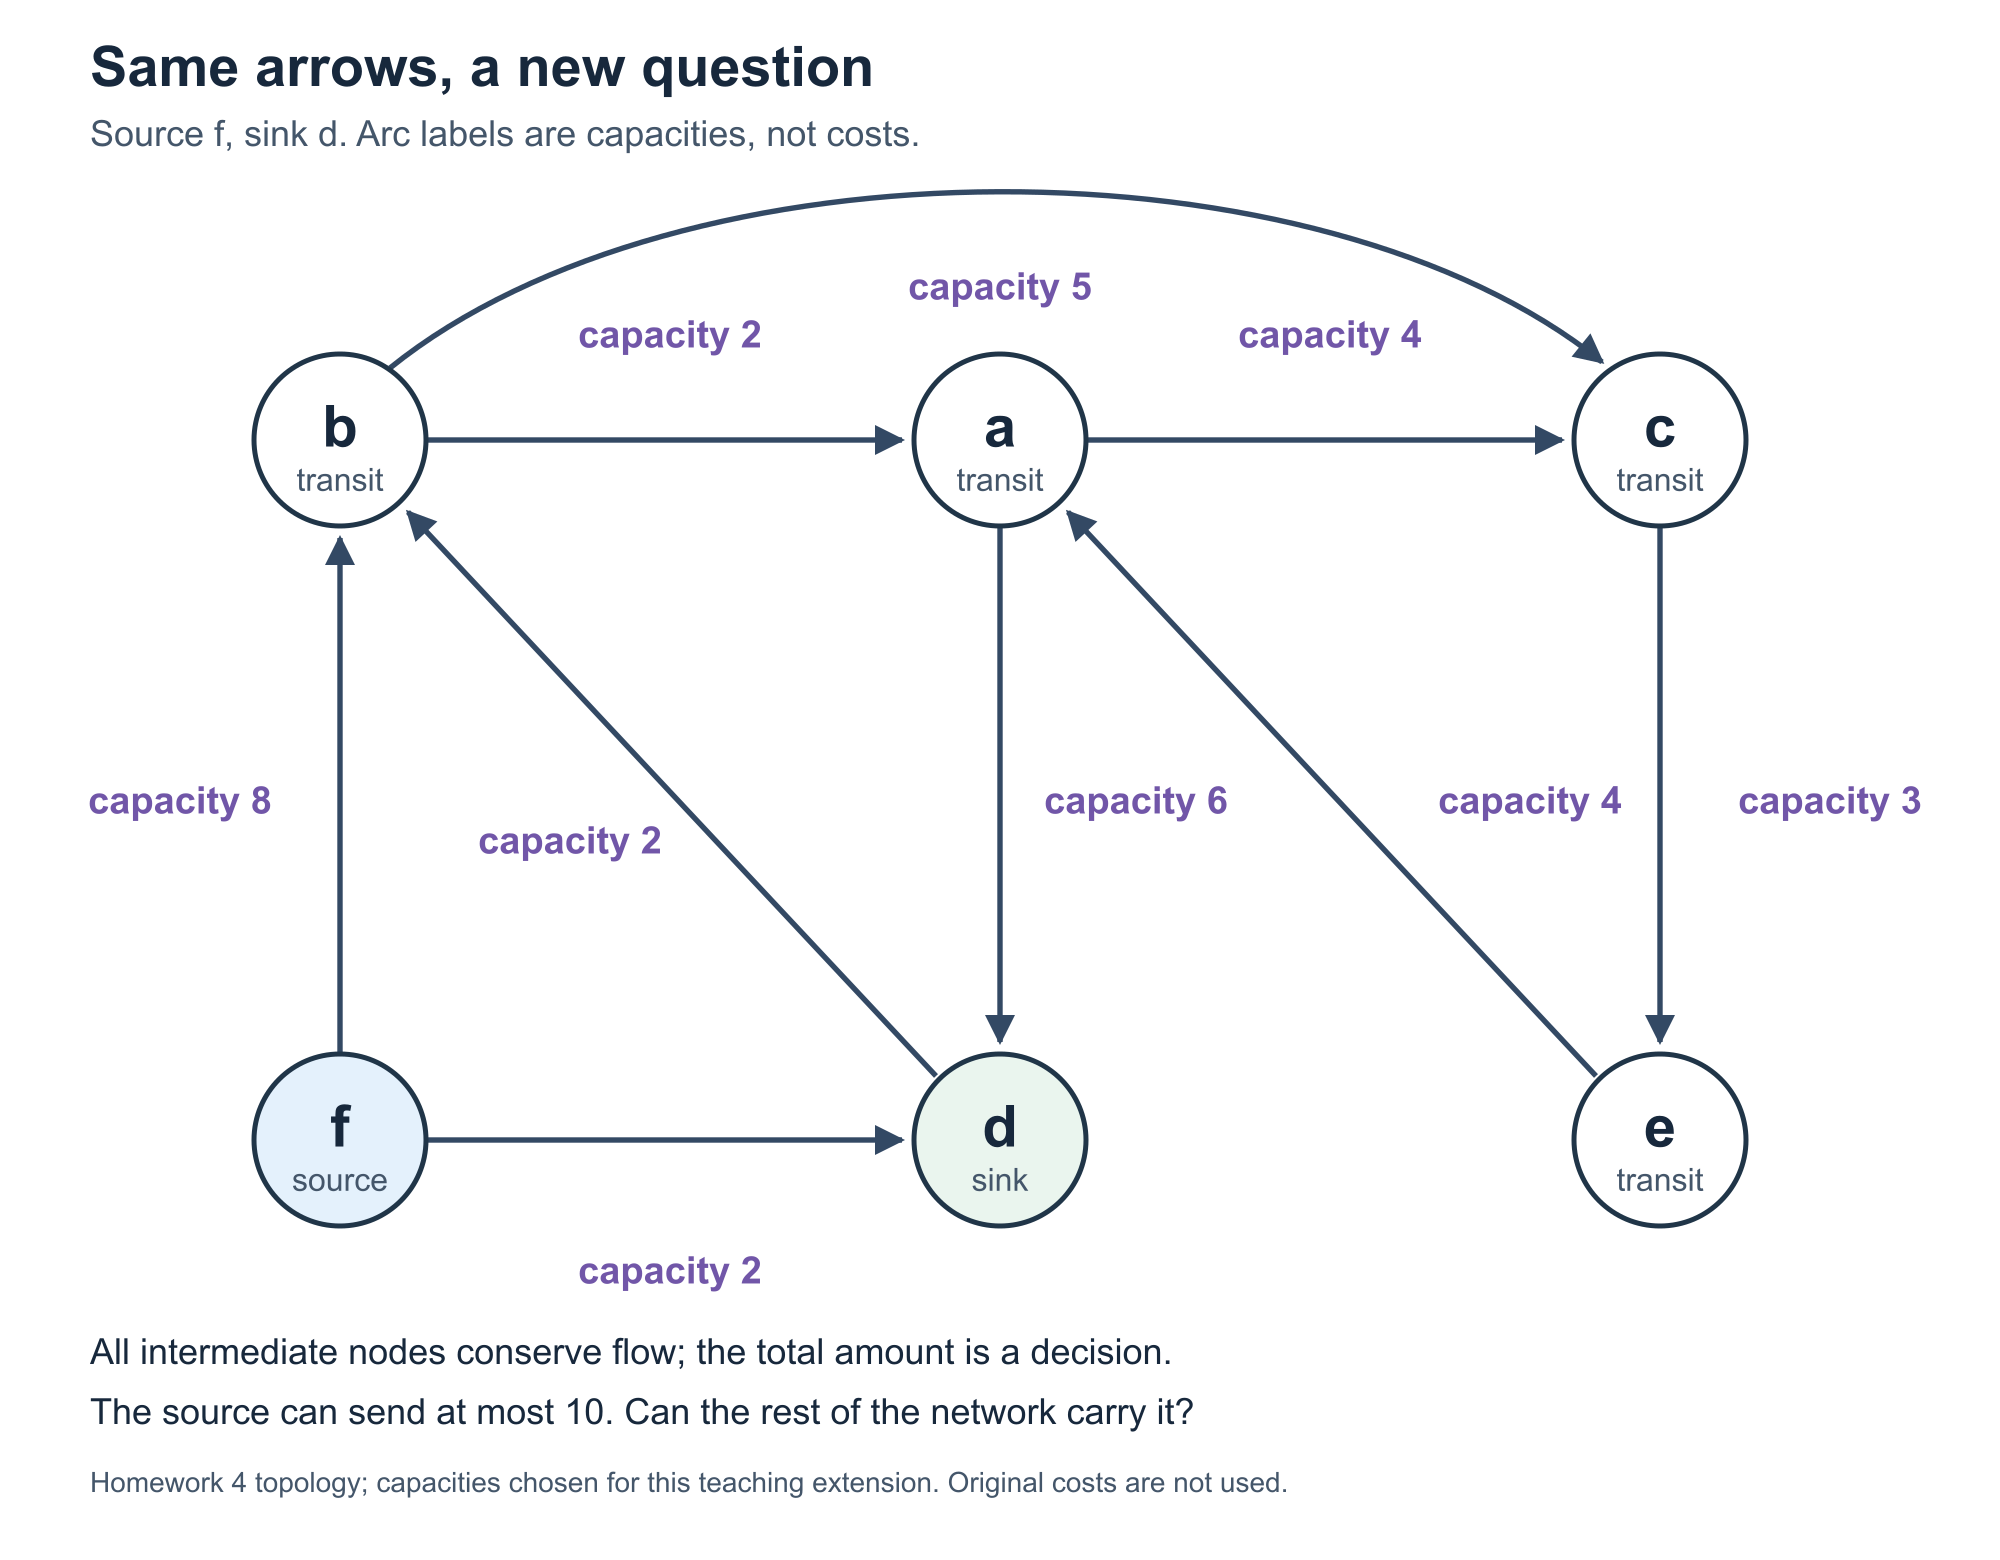

**Predict before coding:** The source can send up to $8+2=10$ units along its
outgoing arcs. Does that guarantee all 10 can reach $d$? Look for a bottleneck.

Allow about 12–15 minutes for the expanded explanation, plus experiments.
For the shorter 60-minute route, run the supplied model promptly and do the
reachability walk by hand; leave the search-code details for later reading.


### Write the maximum-flow linear program

Let $x_{ij}$ be the flow on arc $i\to j$, let $u_{ij}$ be that arc's capacity,
and let $F$ be the total amount delivered. Maximize $F$, conserve flow at
intermediate nodes, and respect every capacity.

$$
\begin{alignedat}{3}
\text{maximize}\quad & F \\[6pt]
\text{subject to}\quad
 & x_{fb}+x_{fd}              &\;&= &\;&F  \quad\text{(source f)} \\
 & x_{db}-x_{ad}-x_{fd}       &&= &&-F \quad\text{(sink d)} \\
 & x_{ac}+x_{ad}-x_{ba}-x_{ea} &&= &&0  \quad\text{(node a)} \\
 & x_{ba}+x_{bc}-x_{db}-x_{fb} &&= &&0  \quad\text{(node b)} \\
 & x_{ce}-x_{ac}-x_{bc}       &&= &&0  \quad\text{(node c)} \\
 & x_{ea}-x_{ce}             &&= &&0  \quad\text{(node e)} \\
 & 0\le x_{ij}              &&\le &&u_{ij}\quad\text{for every arc }i\to j, \\
 & F                        &&\ge &&0.
\end{alignedat}
$$

The sink still has an outgoing arc, $d\to b$, so $F$ is its **net** inflow.
The balance equations make the amount sent by the source equal to the amount
received by the sink. All variables remain continuous.

### Put capacities on the decision variables

We can enforce an arc capacity with the variable's upper bound, `ub`.
Most declarations are supplied. Complete the two missing capacities from the table.

We use new names such as `flow_ac` so the earlier minimum-cost model stays available.

In [ ]:
import gurobipy as gp
from gurobipy import GRB

max_flow = gp.Model("max_flow_extension")

# Each upper bound is the capacity of that arc in this new example.
flow_ac = max_flow.addVar(lb=0, ub=4, name="flow_ac")
flow_ad = max_flow.addVar(lb=0, ub=6, name="flow_ad")
# Complete the capacities of b-to-a and c-to-e using the table.
flow_ba = max_flow.addVar(lb=0, ub=___, name="flow_ba")
flow_bc = max_flow.addVar(lb=0, ub=5, name="flow_bc")
flow_ce = max_flow.addVar(lb=0, ub=___, name="flow_ce")
flow_db = max_flow.addVar(lb=0, ub=2, name="flow_db")
flow_ea = max_flow.addVar(lb=0, ub=4, name="flow_ea")
flow_fb = max_flow.addVar(lb=0, ub=8, name="flow_fb")
flow_fd = max_flow.addVar(lb=0, ub=2, name="flow_fd")

# This decision variable measures how much reaches the sink, net of outflow.
total_flow = max_flow.addVar(lb=0, name="total_flow")

### Conserve flow and connect the source to the sink

The four intermediate-node balances are supplied. Their right-hand sides are
now zero, including at nodes that had supply or demand in Homework 4.

Complete the two terminal balances using the unknown amount `total_flow`.
**Check:** Why is the sink's right-hand side negative?

In [ ]:
# Every intermediate node now has zero net supply.
max_flow.addConstr(flow_ac + flow_ad - flow_ba - flow_ea == 0, name="balance_a")
max_flow.addConstr(flow_ba + flow_bc - flow_db - flow_fb == 0, name="balance_b")
max_flow.addConstr(flow_ce - flow_ac - flow_bc == 0, name="balance_c")
max_flow.addConstr(flow_ea - flow_ce == 0, name="balance_e")

# Fill in the variable for the unknown amount sent and received.
# Keep outflow minus inflow on the left in both equations.
max_flow.addConstr(flow_fb + flow_fd == ___, name="source_f")
max_flow.addConstr(flow_db - flow_ad - flow_fd == -___, name="sink_d")

### Ask Gurobi for the largest possible flow

Complete the objective direction, then solve. This model optimizes the amount
delivered. There is no cost objective in this new question.

In [ ]:
# Should this objective use MAXIMIZE or MINIMIZE? Complete the direction.
max_flow.setObjective(total_flow, GRB.___)
max_flow.optimize()

### Read the flow and check its feasibility

Run the supplied report. It shows each flow beside its capacity; `.UB` reads
the upper bound we set for that variable.

**Check with a partner:** Is every flow within its capacity? Do the intermediate
nodes conserve flow? Keep the total value in mind while looking for an upper bound.

In [ ]:
if max_flow.Status == GRB.OPTIMAL:
    print("Maximum flow =", total_flow.X)
    print("Arc: quantity; capacity")
    print("ac: quantity =", flow_ac.X, "; capacity =", flow_ac.UB)
    print("ad: quantity =", flow_ad.X, "; capacity =", flow_ad.UB)
    print("ba: quantity =", flow_ba.X, "; capacity =", flow_ba.UB)
    print("bc: quantity =", flow_bc.X, "; capacity =", flow_bc.UB)
    print("ce: quantity =", flow_ce.X, "; capacity =", flow_ce.UB)
    print("db: quantity =", flow_db.X, "; capacity =", flow_db.UB)
    print("ea: quantity =", flow_ea.X, "; capacity =", flow_ea.UB)
    print("fb: quantity =", flow_fb.X, "; capacity =", flow_fb.UB)
    print("fd: quantity =", flow_fd.X, "; capacity =", flow_fd.UB)
else:
    print("Solve status:", max_flow.Status)

### First construct a feasible flow of 7

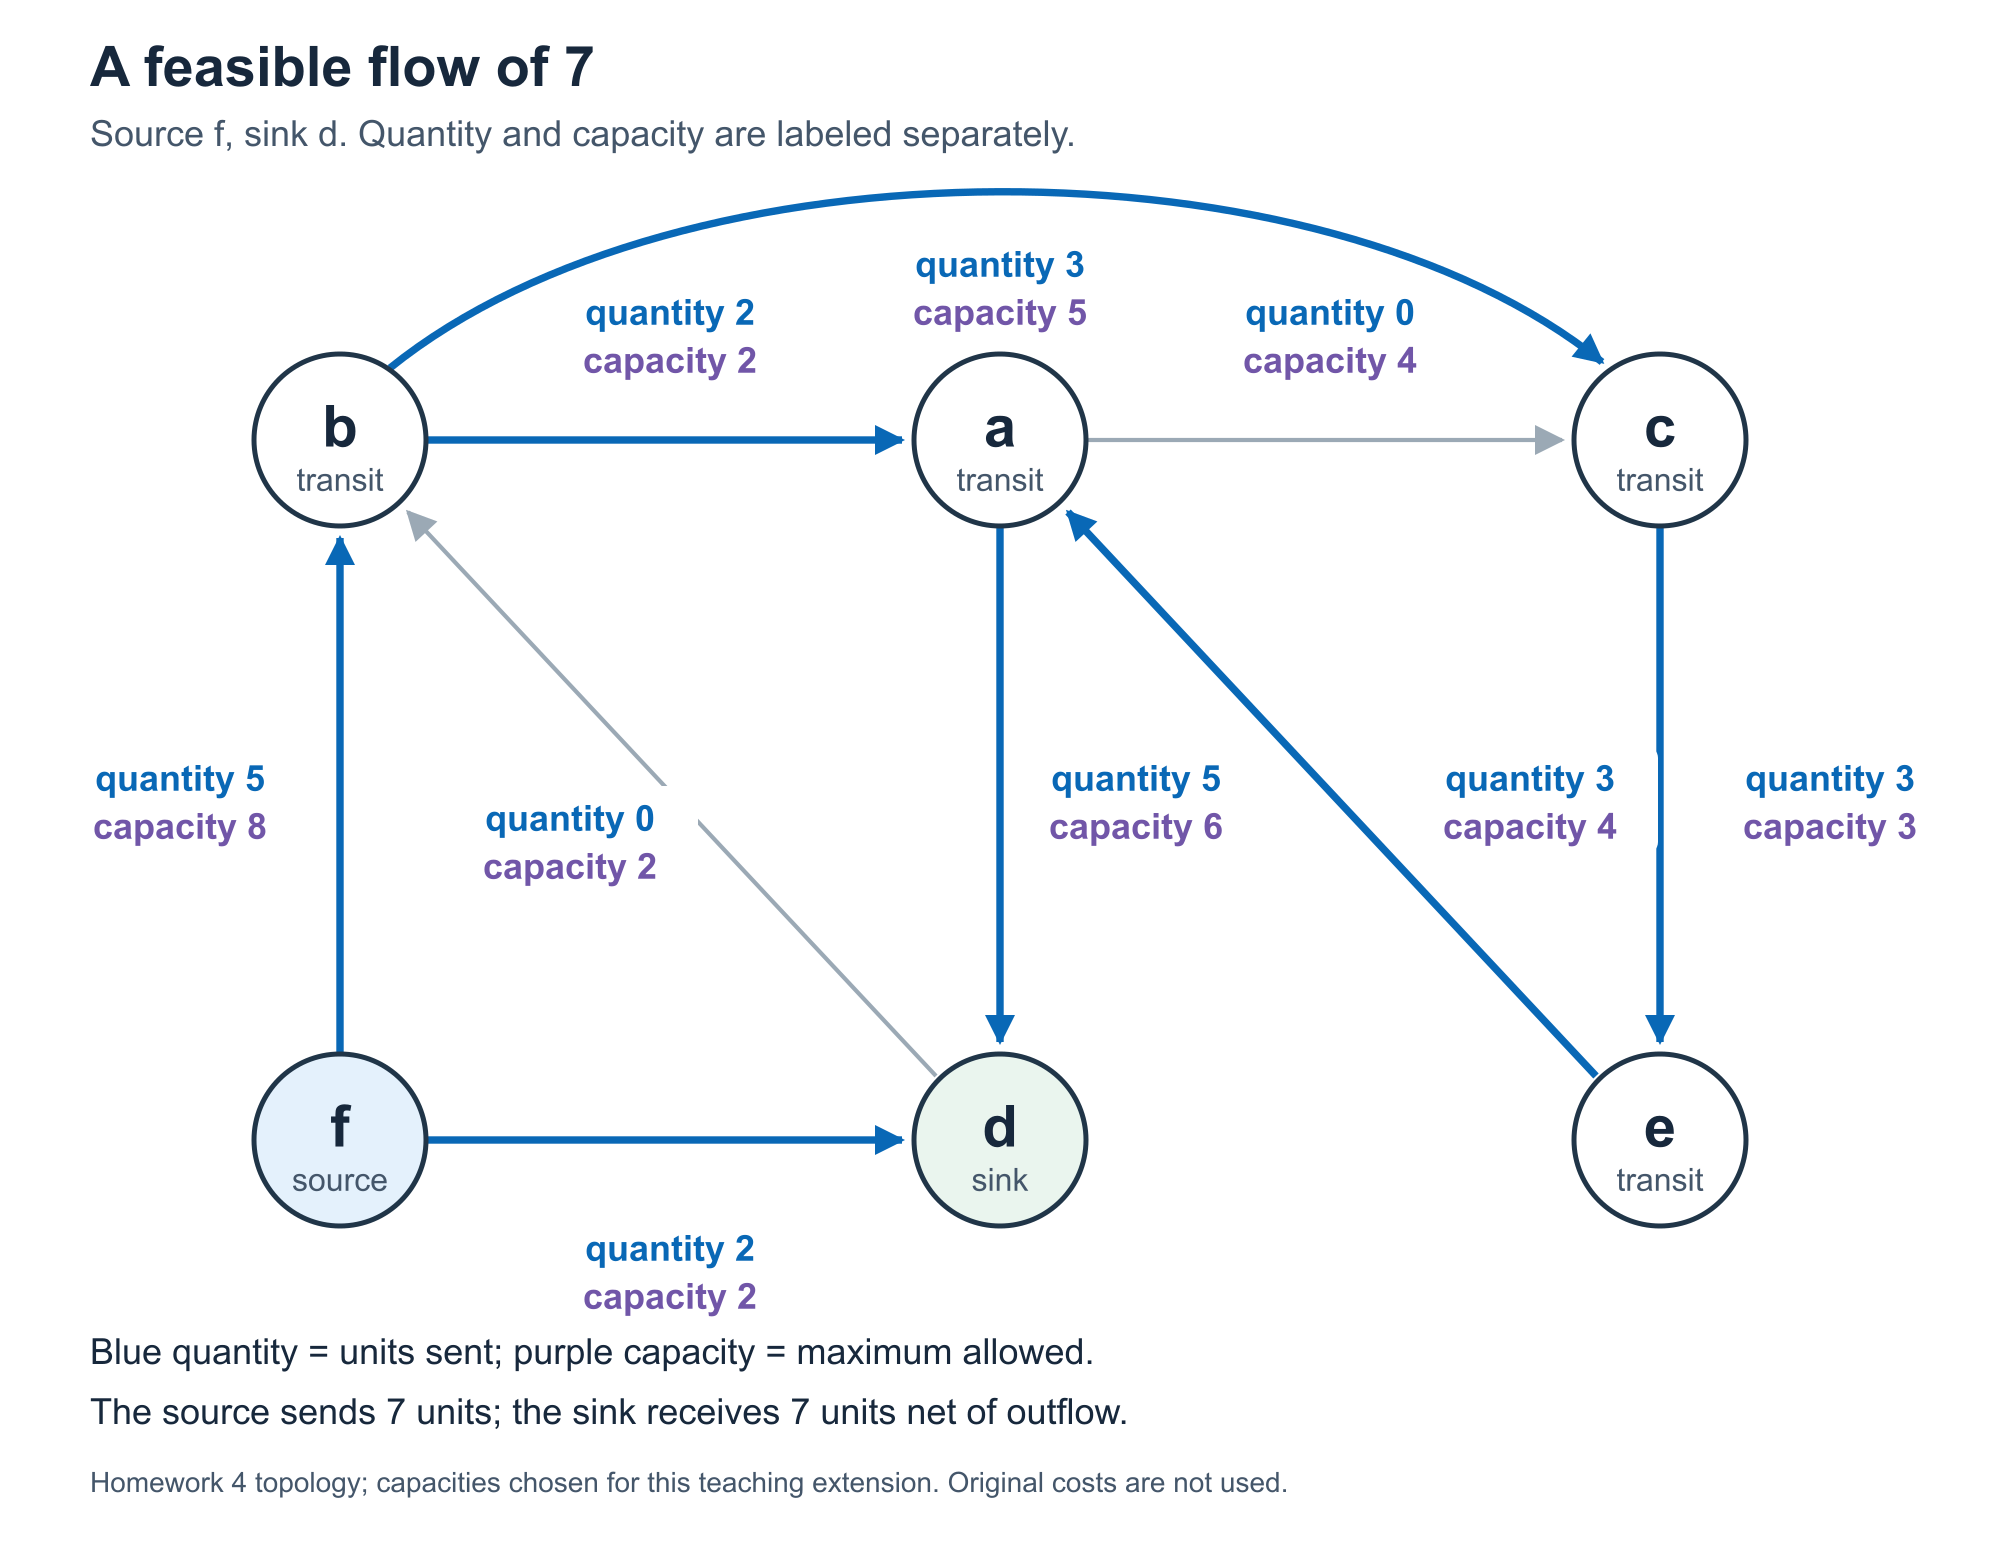

We can build a feasible flow by sending 2 units on $f\to d$, then 2 on
$f\to b\to a\to d$, then 3 on $f\to b\to c\to e\to a\to d$.
The accumulated quantities satisfy every capacity and transit balance.

This is a hand construction we can check; it is not a trace of Gurobi's internal
algorithm. Gurobi solved the LP and found a flow of the same value, **7**.
Finding this feasible plan proves we can send at least 7. We still need an
upper bound to rule out a plan sending 8.

### What is a cut, and why should it limit flow?

A **cut** separates the nodes into two groups: $S$ contains the source $f$,
and $T$ contains the sink $d$. Every route from source to sink must cross
from $S$ to $T$ at least once.

Add the capacities of **all original arrows leaving $S$**. This is the cut's
capacity. Removing those arrows would block every source-to-sink route.
We minimize this sum over all choices of $S$, not over single arcs.

For orientation, $S=\{f\}$ gives capacity $8+2=10$.
Putting every node except $d$ in $S$ gives capacity $6+2=8$.
Both are valid limits, but we can find a tighter one.

**Pause:** Does a cut have to be a single arrow? Does choosing a valid cut already
show that it has the smallest capacity?

### Find the cut from the flow, rather than guessing it

Gurobi solved the maximum-flow **linear program**. We now inspect that solution
to find a cut; we are not running a second optimization model.

Imagine trying to improve the flow. Along an original arrow $i\to j$:

- We can send more forward if $u_{ij}-x_{ij}>0$.
- We can move backward in this improvement calculation if $x_{ij}>0$: that
  means **undo some existing shipment**, not add a new physical reverse route.

These possible adjustments form the **residual network**. Starting at $f$, mark
every node reachable using positive residual capacity, including backward moves.
The marked nodes become $S$. For an optimal flow, $d$ will not be reachable.
Otherwise an improving source-to-sink adjustment would still exist.

**Important:** Looking only for unused forward capacity can miss rerouting
opportunities. That is why the supplied code includes backward adjustments.

### Walk through our solution by hand

Our flow sends 5 on $f\to b$, 2 on $f\to d$, 2 on $b\to a$,
3 on $b\to c$, and 3 on $c\to e$.

| Step | What can still change? | Newly reachable node |
|---|---|---|
| Start at $f$ | $f\to b$ has $8-5=3$ spare units. $f\to d$ has none. | $b$ |
| Inspect $b$ | $b\to c$ has $5-3=2$ spare units. $b\to a$ is full at 2. | $c$ |
| Inspect $c$ | $c\to e$ is full at 3. No remaining move reaches a new node. | None |

Also check backward moves: $b\to d$ would undo flow on $d\to b$, but that
flow is zero. Likewise, $c\to a$ would undo flow on $a\to c$, which is zero.
Other available backward moves only revisit nodes already marked.

We have reached exactly **$S=\{f,b,c\}$**, leaving **$T=\{a,d,e\}$**.
The source still has spare capacity, but there is no residual way to carry
additional flow all the way to the sink.

The next cell automates this walk. Its loops are supplied; focus on the two
residual-capacity tests and the sets it prints.

In [ ]:
# Supplied helper: find a cut from the current optimal flow.
# Run after the maximum-flow solve and before the capacity experiments.
if max_flow.Status != GRB.OPTIMAL:
    raise RuntimeError("Solve the maximum-flow model first.")

arc_variables = {
    "ac": flow_ac, "ad": flow_ad, "ba": flow_ba,
    "bc": flow_bc, "ce": flow_ce, "db": flow_db,
    "ea": flow_ea, "fb": flow_fb, "fd": flow_fd,
}
tol = 1e-6  # Ignore tiny numerical roundoff.
residual_neighbors = {node: [] for node in "abcdef"}
for arc, variable in arc_variables.items():
    tail, head = arc
    # Forward: room to send more. Backward: room to undo existing flow.
    if variable.UB - variable.X > tol:
        residual_neighbors[tail].append(head)
    if variable.X > tol:
        residual_neighbors[head].append(tail)

source_side = {"f"}
to_visit = ["f"]
while to_visit:
    node = to_visit.pop()
    for neighbor in residual_neighbors[node]:
        if neighbor not in source_side:
            source_side.add(neighbor)
            to_visit.append(neighbor)

sink_side = set("abcdef") - source_side
cut_arcs_found = [arc for arc in arc_variables
                  if arc[0] in source_side and arc[1] in sink_side]
cut_capacity_found = sum(arc_variables[arc].UB for arc in cut_arcs_found)
print("Source side S =", sorted(source_side))
print("Sink side T =", sorted(sink_side))
print("Arcs leaving S =", cut_arcs_found)
print("Cut capacity =", cut_capacity_found)
print("Flow value =", total_flow.X)


### Read the boundary we discovered

The search found $S=\{f,b,c\}$ and $T=\{a,d,e\}$. The original arrows
leaving $S$ are $b\to a$, $c\to e$, and $f\to d$:

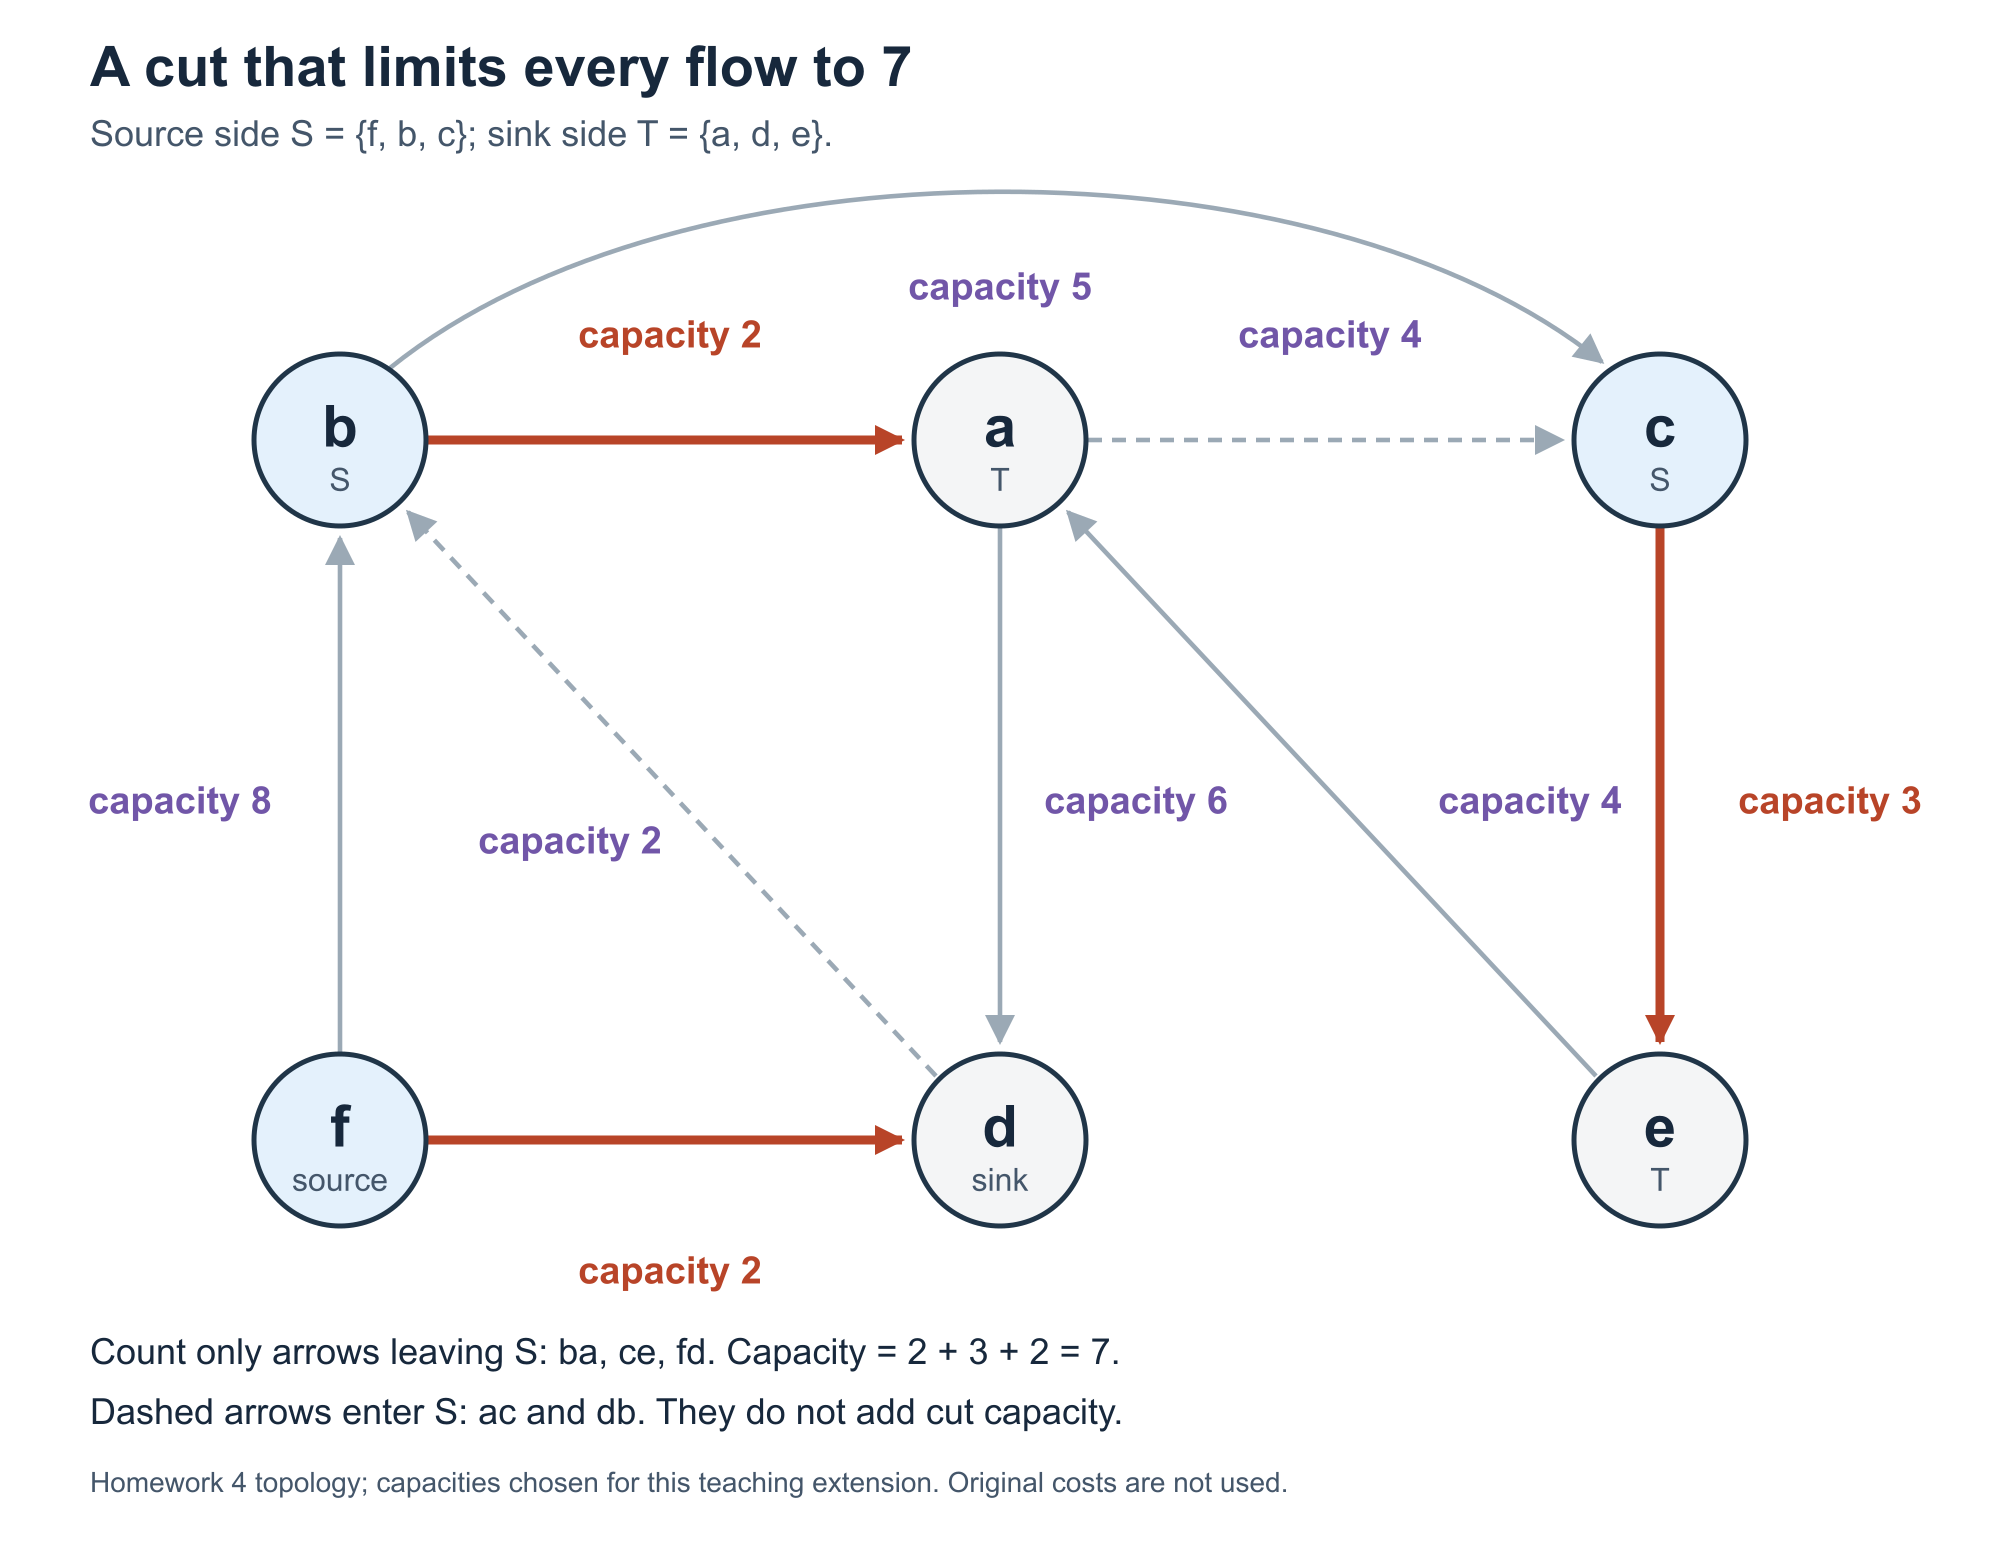

$$\text{cut capacity}=u_{ba}+u_{ce}+u_{fd}=2+3+2=7.$$

The dashed arrows in this figure are **original arrows entering $S$**. This
picture shows the cut in the original network, not the residual network.

Why does 7 limit every feasible flow? Add the balances for $f$, $b$, and $c$.
Internal flows cancel; what leaves this group minus what enters it must equal $F$:

$$
\begin{aligned}
F&=x_{ba}+x_{ce}+x_{fd}-x_{ac}-x_{db}\\
 &\le x_{ba}+x_{ce}+x_{fd}\\
 &\le u_{ba}+u_{ce}+u_{fd}=7.
\end{aligned}
$$

Incoming flow cannot increase net delivery out of $S$. We subtract it; we do
not add the capacities of those incoming arrows to the cut.

**Check:** Is the cut capacity computed using quantities currently shipped,
or maximum quantities allowed on its outgoing arrows?

### Why is this cut actually minimum?

The word *minimum* needs its own argument. We have two checkable facts:

1. A feasible flow of **7** exists.
2. The cut we found has capacity **7**.

Any feasible flow is at most the capacity of **every** source–sink cut.
Therefore, our feasible flow of 7 rules out a cut of capacity 6, or any value
below 7. Since we have found a cut of capacity 7, it is a minimum cut.

The same two facts also prove that the flow is maximum:

$$\underbrace{7}_{\text{feasible flow}}
\;\le\; F^* \;\le\;
\underbrace{7}_{\text{cut capacity}}.$$

**Pause:** What rules out a flow of 8? What rules out a cut of 6?
The cut rules out the first; the feasible flow rules out the second.
We do not need to enumerate all cuts once these matching values are verified.

### Match the feasible flow with the cut

Complete the cut-capacity calculation using the upper bounds in the Gurobi model.
Then compare the feasible flow value with this upper bound.

$$7\;\le\;F^*\;\le\;7.$$

We have both a maximum flow and a minimum cut: no flow can beat the cut bound,
and no cut can have capacity below a feasible flow of the same value.
The **max-flow/min-cut theorem** says that matching optima exist for every
finite directed network with nonnegative, finite capacities.

This is a concrete preview of duality: one feasible object supplies a lower
bound, another supplies an upper bound, and equality certifies optimality.

The supplied residual search **finds** the cut; this arithmetic **checks** it.

Further reading: [Princeton's network-flow notes](https://algs4.cs.princeton.edu/64maxflow/).

In [ ]:
# Complete the missing arc that crosses from S = {f, b, c} to its complement.
# Add capacities (.UB), rather than the flows currently using those arcs.
cut_capacity = flow_ba.UB + ___.UB + flow_fd.UB

if max_flow.Status == GRB.OPTIMAL:
    print("Feasible flow value =", total_flow.X)
    print("Cut capacity =", cut_capacity)
    print("Upper bound minus lower bound =", cut_capacity - total_flow.X)

### The bottleneck is a boundary across the network

The three outgoing cut arcs are all full: $b\to a$ carries 2 of 2,
$c\to e$ carries 3 of 3, and $f\to d$ carries 2 of 2. Together they form
a **7-unit bottleneck** separating the reachable source side from the sink side.
The original arcs entering $S$, $a\to c$ and $d\to b$, carry zero.

A full arc by itself does not prove a bottleneck: another route might bypass it.
Here, the entire outgoing boundary is full, so every source–sink route is covered.

Increasing $f\to b$ from 8 to 10 adds room **before** that boundary. It does not
change its capacity of 7, so it cannot raise the maximum flow.

Increasing $c\to e$ from 3 to 4 changes the boundary itself. In this example,
we can send one more unit on $f\to b\to c\to e\to a\to d$: the other arrows
on that route also have room. The maximum becomes 8. Our original partition now
has capacity $2+4+2=8$ and is still minimum. The cut around the sink also has
capacity $u_{ad}+u_{fd}=6+2=8$: **minimum cuts need not be unique**.

The supplied search still returns $S=\{f,b,c\}$, now with capacity 8. The sink
cut is another equally good certificate. Increasing $c\to e$ again by itself
cannot beat the unchanged 8-unit cut around the sink.

In general, increasing one arc in a minimum cut need not improve the answer:
another equally restrictive cut may remain. Here the extra feasible unit and
the new cut of 8 confirm the improvement.

### Optional experiment: more capacity at the source

Increase the capacity of $f\to b$ from 8 to 10. Predict the new maximum before
running the cell. Does this change any capacity in our cut of value 7?

Re-run the supplied cut-search cell after this solve to discover and check the current minimum cut.


In [ ]:
# Optional experiment 1: allow more flow to leave the source.
flow_fb.UB = 10
max_flow.optimize()
if max_flow.Status == GRB.OPTIMAL:
    print("After increasing f-to-b capacity: maximum flow =", total_flow.X)
else:
    print("Solve status:", max_flow.Status)

### Optional experiment: widen a bottleneck

Now increase the capacity of $c\to e$ from 3 to 4 and solve again.
The earlier $f\to b$ change remains in effect.

**Predict:** Does the old cut still cap the flow at 7? After solving, explain
why improving this arc helps while improving the source arc did not.

Re-run the supplied cut-search cell after this solve to discover and check the current minimum cut.


In [ ]:
# Optional experiment 2: increase one capacity in the limiting cut.
flow_ce.UB = 4
max_flow.optimize()
if max_flow.Status == GRB.OPTIMAL:
    print("After increasing c-to-e capacity: maximum flow =", total_flow.X)
else:
    print("Solve status:", max_flow.Status)

### Explain the certificate in your own words

1. What does a feasible flow of 7 prove for a maximization problem?
2. What does a cut of capacity 7 prove, and why does the direction of its arrows matter?
3. Why did increasing $f\to b$ leave the maximum unchanged?

**After the experiments:** The maximum rises to 8. The two arcs entering $d$,
$a\to d$ and $f\to d$, have total capacity $6+2=8$. This gives another matching
cut: put every node except $d$ in $S$.

The cut is a bottleneck across the network, not necessarily a single arc.
More capacity helps only if it relaxes a limit that is actually restricting the flow.

## 5. A brief look at bounds and the gap

The **primal** is the problem we wrote. Its **dual** is a companion optimization
problem built from the same constraints. Feasible dual solutions provide bounds
on the best possible primal value. We will learn how to construct the dual later.

| Goal | A feasible primal solution gives | A feasible dual solution gives |
|---|---|---|
| Maximize revenue | A lower bound | An upper bound |
| Minimize cost | An upper bound | A lower bound |

$$\text{gap}=\text{upper bound}-\text{lower bound}.$$

The gap bounds how much improvement may remain. For our network, a feasible
cost of 43 is an upper bound. Nonnegative costs give a simple lower bound of 0.
Together, these tell us the minimum lies in $[0,43]$.

**A solver-log example: the original 200-minute bag problem**

```text
                  Objective                Residual
Iter       Primal          Dual         Primal    Dual     Compl
   5   2.19285504e+02  2.19285808e+02  2.73e-12 0.00e+00  5.07e-05
   7   2.19285714e+02  2.19285714e+02  1.17e-13 0.00e+00  5.07e-11
Optimal objective 2.19285714e+02
```

At the end of this barrier-method run, the primal and dual objectives approach
219.285714 and the feasibility residuals are close to zero. Matching feasible
bounds certify optimality within numerical tolerances.

**Reading tip:** Early barrier iterates can be infeasible, so their objectives
are not automatically valid bounds. In a simplex log, `Dual Inf.` means dual
infeasibility; it is not the objective gap.

## 6. Use an LLM to help you build and check a model

An LLM can help explain syntax, translate a formulation, and debug a small code
fragment. Keep the mathematical decisions visible so you can check its work.

A useful sequence is **formulate → translate → run → verify**. Ask for one
manageable step at a time, and keep a working copy before trying a suggested change.

These tips take about 3 minutes to discuss and can also be read after class.

### Why ask an LLM to use Gurobi instead of just giving an answer?

An LLM can help formulate a problem, explain syntax, and write code. Asking it to
**actually run an optimization solver** gives us an explicit model and a
computation we can inspect: constraints, solution values, solve status, and bounds.

| Question | What should we check? |
|---|---|
| Did we model the story correctly? | Match the variables and every constraint to the original requirements. |
| Is this proposed plan feasible? | Substitute its values into every original constraint. |
| Could any feasible plan be better? | Check a valid optimality argument or the solver's bounds and termination status. |

A correct, checkable mathematical proof from an LLM is useful too. A confident
claim of optimality alone does not establish it. If an LLM already calls a solver,
it is using this same combined workflow.

Gurobi's `OPTIMAL` status means the **encoded model** was solved to optimality
subject to numerical tolerances. A time limit may leave a gap. We still need to
check that the encoded model matches the story.
([Gurobi status definitions](https://docs.gurobi.com/projects/optimizer/en/current/reference/numericcodes/statuscodes.html).)

### Return to Homework 4: a feasible answer can still be expensive

Suppose an LLM proposes the flow we checked earlier:
$ac=1$, $ad=4$, $bc=3$, $ea=5$, $fd=2$, with all other flows zero.
Every node balance holds, and its cost is

$$0(1)+1(4)+3(3)+2(5)+10(2)=43.$$

This is a valid plan. Checking the balances does **not** show it is cheapest.

| Result | Actual arc cost | What have we established? |
|---|---:|---|
| Checked candidate flow | 43 | Feasible; the minimum cost is at most 43. |
| Gurobi solve with objective zero | Depends on the returned flow | Feasible; `OPTIMAL` refers to the constant objective. |
| Gurobi solve minimizing the actual arc costs | 35 | Optimal for the cost model, subject to numerical tolerances. |

The cheaper flow is $ad=6$, $bc=5$, $ce=1$, $ea=6$, $fb=2$, with all other flows
zero. Its cost is $1(6)+3(5)+2(1)+2(6)+0(2)=35$.

**Pause and discuss:** If all we know is that a flow costs 35 and satisfies every
balance, have we ruled out a flow costing 34? What additional evidence do we need?

We need an optimality argument, such as a valid lower bound of 35, or a solver's
optimal termination for the correct cost objective. Finding a cheaper feasible
plan improves our answer; establishing optimality rules out any further improvement.

### Start with the algebra and the meaning of the variables

Include variable definitions, units, bounds, types, objective direction, and
constraints. Ask the LLM to identify any ambiguity before writing code.

Try this prompt after supplying your formulation:

```text
Translate this mathematical model into Python using gurobipy. Use the simple
addVar, addConstr, setObjective, and optimize calls from our lesson.
Keep my variable types and constraint directions. Explain how each code line
corresponds to the algebra. Ask about missing information instead of inventing data.
```

**Check:** Could you explain each returned constraint in words, including its units?

### Debug the smallest relevant piece

Provide the code, the exact error, and your Python/Gurobi versions. Distinguish
a Python error from a model reported as infeasible. Omit license keys and credentials.

```text
Here is my gurobipy code and the exact error or solve status.
Explain the cause and suggest the smallest correction. Preserve the intended
mathematics. If the constraints conflict, identify the conflict and explain it;
do not remove a requirement just to obtain an optimal status.
```

After changing a constraint that you already added, rebuild the model from the
top. Editing a notebook cell does not remove the old constraint from memory.

### Verify the answer yourself

Before accepting generated code or a suggested solution:

1. Match each code constraint to the algebra, including its sign and units.
2. Check bounds, integer types, and whether the objective should be minimized or maximized.
3. Run the code and check the solve status before reading solution values.
4. Substitute the returned values into the original requirements.
5. Compare with a known feasible plan or a valid bound when you have one.

For example, the proposed plan $h=39$, $s=7$ fails the machine constraint even
though its revenue looks attractive. A fluent explanation does not make it feasible.

```text
Review my formulation and code side by side. First check whether they match.
Then check the reported solution by substituting it into each original constraint.
Explain any discrepancy; do not claim a Gurobi result unless the code was actually run.
```

Gurobi certifies the model it receives. You still need to check that the model
represents the problem you meant to solve.

Keep the [official Python API reference](https://docs.gurobi.com/projects/optimizer/en/current/reference/python/model.html)
nearby when checking method names and attributes.

## Check your understanding

Take a moment to answer these on your own.

1. Write the outflow-minus-inflow balance at node $c$.
2. Why does `OPTIMAL` after `net.setObjective(0)` not establish minimum arc cost?
3. Why is rounding the bag LP solution unsafe? Which constraint did it violate?

**If time permits:** Explain why negative `ad` changes our directed network.
If we have discussed bounds, use feasible cost 43 and a valid lower bound of 35
to give the possible optimal interval and the gap.

Rebuild the model from the top after correcting a constraint already added.


## If we have more time

What happens if the bag machine capacity increases from 200 to 210 minutes?
Predict the effect on the best revenue before changing the model. This experiment
and a network model using loops are included in the optional lesson files.

References: [Gurobi's Python Model API](https://docs.gurobi.com/projects/optimizer/en/current/reference/python/model.html),
[barrier logs](https://docs.gurobi.com/projects/optimizer/en/current/concepts/logging/barrier.html),
and [simplex logs](https://docs.gurobi.com/projects/optimizer/en/current/concepts/logging/simplex.html).